
Q1. Explain the difference between Sigmoid and ReLU activation functions. When would you prefer one over the other?
Answer:
Sigmoid	ReLU
Output range: 0 to 1	Output range: 0 to ∞
Used for probability	Used for hidden layers
Slower computation	Faster computation
Can cause vanishing gradients	Reduces vanishing gradient problem

Formulas:
- Sigmoid: \(f(x)=\frac{1}{1+e^{-x}}\)
- ReLU: \(f(x)=\max(0,x)\)
When to use:
- Sigmoid: Binary classification output layer.
- ReLU: Hidden layers in deep neural networks.
Remember: Sigmoid = Probability; ReLU = Hidden layers.

Q2. What is the vanishing gradient problem? How does Batch Normalization help address it?
Answer:

Vanishing Gradient: It occurs when gradients become extremely small during backpropagation in deep neural networks. As a result, earlier layers learn very slowly.

How Batch Normalization helps:
1. Normalizes inputs to each layer.
2. Maintains stable data distribution.
3. Improves training speed.
4. Makes learning more stable.
Remember: Vanishing Gradient = Very small gradients; Batch Normalization = Stable and faster training.

Q3. Name the three gates in an LSTM cell and briefly state the role of each.
Answer:

LSTM (Long Short-Term Memory) has three gates:

Gate	Function
1. Forget Gate	Removes unnecessary old information.
2. Input Gate	Adds new information to memory.
3. Output Gate	Decides information passed as output.

Remember:
- Forget = Remove
- Input = Add
- Output = Share

Q4. Write the Bellman optimality equation for the state-action value function Q*(s,a).
Answer:

The Bellman optimality equation is:
\[
Q^*(s,a)=\sum_{s',r}P(s',r|s,a)
\left[r+\gamma\max_{a'}Q^*(s',a')\right]
\]

Where:
Symbol	Meaning
\(Q^*(s,a)\)	Optimal action value
\(s\)	Current state
\(a\)	Current action
\(r\)	Immediate reward
\(\gamma\)	Discount factor
\(s'\)	Next state
\(P\)	Transition probability

Remember:

Optimal Q-value = Immediate Reward + Discounted Future Reward.

Q5. Explain the exploration vs exploitation dilemma in RL with a real-world analogy.
Answer:

In Reinforcement Learning:
- Exploration: Trying new actions to discover better rewards.
- Exploitation: Choosing the best-known action to get maximum reward.
Real-world example: Restaurant selection
Exploration	Exploitation
Trying a new restaurant.	Visiting your favourite restaurant.
Discovering new options.	Choosing a known good option.
More uncertainty.	Less uncertainty.

Remember:
- Exploration = Try something new.
- Exploitation = Use what you know.
The RL agent must balance both to achieve maximum long-term reward.

Quick revision – 5 questions
Question	One-line answer
Q1. Sigmoid vs ReLU	Sigmoid = Probability; ReLU = Hidden layers
Q2. Vanishing Gradient	Gradients become very small
Q3. LSTM gates	Forget, Input, Output
Q4. Bellman equation	Reward + Discounted Future Reward
Q5. Exploration vs Exploitation	Try new vs Choose best-known

1. Sigmoid vs ReLU

Sigmoid: σ(x) = 1 / (1 + e⁻ˣ), output in (0, 1).
ReLU: f(x) = max(0, x), output in [0, ∞).

Aspect	Sigmoid	ReLU
Gradient	Max 0.25; near 0 for large |x| (saturates)	1 for x > 0, 0 for x < 0
Output centering	Not zero-centered	Not zero-centered, but sparse
Compute cost	Expensive (exponential)	Very cheap
Main issue	Vanishing gradients	"Dying ReLU" (neurons stuck at 0)

Preference:

ReLU (or variants like Leaky ReLU, GELU) for hidden layers in deep networks. It trains faster, gives sparse activations, and avoids saturation for positive inputs.
Sigmoid at the output layer for binary classification (the output is interpreted as a probability), and in gating mechanisms (e.g., LSTM gates) where a 0-1 range is needed.
2. Vanishing Gradient Problem and Batch Normalization

Vanishing gradients: During backpropagation, gradients are computed by the chain rule as products of many per-layer derivatives. If these derivatives are less than 1 (e.g., sigmoid/tanh in saturated regions, or small weights), the product shrinks exponentially with depth. Early layers receive near-zero gradients, so they learn extremely slowly or not at all.

How Batch Norm helps: BatchNorm normalizes each layer's pre-activations to zero mean and unit variance per mini-batch, then applies learnable scale (γ) and shift (β):

x̂ = (x − μ_B) / √(σ²_B + ε), y = γx̂ + β

It keeps inputs to activations in the non-saturating region (e.g., near the steep center of sigmoid/tanh), so derivatives don't collapse.
It stabilizes the distribution of layer inputs (reducing internal covariate shift), preventing activation scales from drifting and gradients from shrinking or exploding.
It makes training less sensitive to weight initialization and allows higher learning rates.
3. The Three Gates in an LSTM Cell
Forget gate (fₜ): Decides what information from the previous cell state Cₜ₋₁ to discard (values near 0 = forget, near 1 = keep).
Input gate (iₜ): Decides which parts of the new candidate values (C̃ₜ) to write into the cell state.
Output gate (oₜ): Decides which parts of the (tanh-squashed) cell state are exposed as the hidden state hₜ, i.e., the output at this step.
4. Bellman Optimality Equation for Q*(s,a)
$$Q^*(s,a) = \sum_{s',r} p(s',r \mid s,a)\left[r + \gamma \max_{a'} Q^*(s',a')\right]$$

Equivalently, in expectation form:

$$Q^*(s,a) = \mathbb{E}\left[R_{t+1} + \gamma \max_{a'} Q^*(S_{t+1}, a') \mid S_t = s, A_t = a\right]$$

where γ ∈ [0, 1] is the discount factor. This is the basis of Q-learning.

5. Exploration vs Exploitation

The dilemma: An agent must choose between exploiting what it already knows to get high reward now, and exploring unfamiliar actions that might yield better long-term reward but risk lower immediate payoff. Too much exploitation can trap the agent in a suboptimal policy; too much exploration wastes reward.

Analogy: Choosing where to eat dinner. You have a favorite restaurant you know is good (exploit). But a new place opened nearby that could be even better, or could be disappointing (explore). If you always go to your favorite, you may never discover a better option; if you always try new places, you often end up with mediocre meals.

Common strategies: ε-greedy (explore with probability ε, often decayed over time), Upper Confidence Bound (UCB), Thompson sampling, and softmax/Boltzmann exploration.


## Section: Deep Learning — DNN on MNIST 

**Dataset:** MNIST Handwritten Digits (built-in via tf.keras.datasets.mnist)
10 classes (digits 0-9), 28x28 grayscale images, flattened to 784-dimensional vectors.

---

#### Section B: Question 1 (20 marks)
Build a **Deep Neural Network (DNN)** using only Dense layers to classify MNIST digits.

**Conditions:**
- Use only Dense (fully connected) layers — no Conv2D or pooling layers
- Minimum 3 hidden layers
- Use Adam Optimizer

**Mark Distribution:**
1. Load MNIST, flatten images to 784-d vectors, normalize to [0,1], one-hot encode labels (5 marks)
2. Build DNN with 3 hidden layers (256, 128, 64 neurons, ReLU) + output (10, softmax). Print summary (5 marks)
3. Compile with categorical_crossentropy + Adam, fit for 10 epochs with validation split (5 marks)
4. Report test accuracy, plot training vs validation accuracy curves, predict 3 random test images (5 marks)


In [2]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, Flatten, LSTM, GRU, SimpleRNN
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
import numpy as np
import matplotlib.pyplot as plt


print("all libraries installed")

all libraries installed


In [97]:
# tf.keras.callbacks.EarlyStopping??

In [3]:
# Step 1: Load MNIST, flatten 28x28 -> 784, normalize, one-hot encode
# Hint: (x_train, y_train), (x_test, y_test) = mnist.load_data()
# x_train = x_train.reshape(-1, 784).astype('float32') / 255.0
# y_train = to_categorical(y_train, 10)
# YOUR CODE HERE
# Step 1: Load MNIST, flatten 28x28 -> 784, normalize, one-hot encode

# Downloads and splits the TensorFlow MNIST dataset into 60,000 training images and 10,000 test images (each 28 × 28 pixels) 
# along with their integer digit labels (0–9)
(x_train,y_train),(x_test,y_test)=mnist.load_data()

# Preserves the original 28 × 28 image grids and single-digit integer labels so you can easily plot images and check predictions later
# Flattening (reshape(-1, 784)): Converts each 28 × 28 2D image into a 1D vector of 784 pixels, which standard Dense layers require.
# Normalization (/ 255.0): Scales raw pixel intensities (0–255) down to the 0.0–1.0 range as 32-bit floats so the model trains faster and more reliably.

x_test_img=x_test.copy()                      # keep 28x28 images for display later
x_train=x_train.reshape(-1,784).astype('float32')/255.0
x_test=x_test.reshape(-1,784).astype('float32')/255.0

# Converts integer labels into 10-element binary vectors (for example, 3 becomes [0, 0, 0, 1, 0, 0, 0, 0, 0, 0]), matching a 10-neuron softmax 
# output layer using categorical_crossentropy loss.
y_test_intlab=y_test.copy()                     # keep integer labels for display
y_train=to_categorical(y_train,10)
y_test=to_categorical(y_test,10)

# The MNIST dataset contains a total of 70,000 handwritten digit images. These images are already divided into two groups:
# - 60,000 images for Training
# - 10,000 images for Testing

print("x_train:",x_train.shape, "y_train:",y_train.shape)
print('x_test',x_test.shape,"y_test",y_test.shape)
print("Pixel Range:",x_train.min(),"-",x_train.max()) # Confirm Normalization was sucessful

x_train: (60000, 784) y_train: (60000, 10)
x_test (10000, 784) y_test (10000, 10)
Pixel Range: 0.0 - 1.0


In [5]:
# Step 2: Build DNN — 3 hidden layers (256, 128, 64) with ReLU + output (10, softmax)
# Use Sequential model with Dense layers only
# Print model.summary()
# YOUR CODE HERE

def build_baseline():
    model=Sequential([
        Dense(256, activation='relu',input_shape=(784,)),
        Dense(128, activation='relu'),
        Dense(64,  activation='relu'),
        Dense(10,activation='softmax')
    ])
    return model
model=build_baseline()
model.summary()




C:\Users\Hp\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 256)                 │         200,960 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 242,762 (948.29 KB)

 Trainable params: 242,762 (948.29 KB)

 Non-trainable params: 0 (0.00 B)

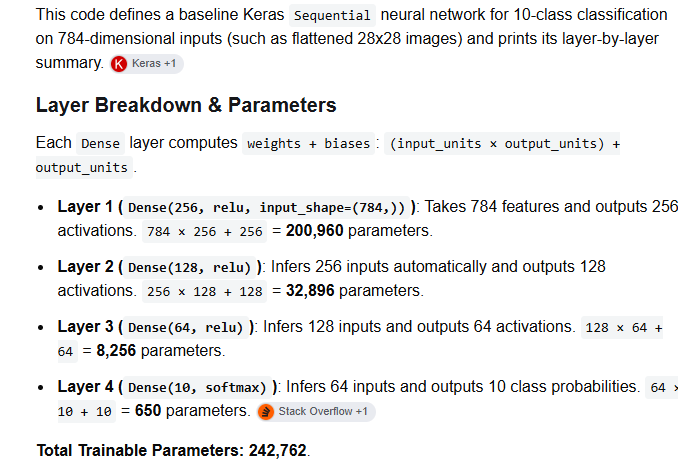

In [6]:
# Step 3: Compile with categorical_crossentropy, Adam optimizer
# Fit for 10 epochs, batch_size=64, validation_split=0.2
# YOUR CODE HERE
#The Keras compile() API prepares the model for training by defining how it updates weights and measures success:
# • optimizer=Adam(). Uses the Adam optimizer, an adaptive learning rate algorithm (defaulting to a learning rate of 0.001) that efficiently 
#  adjusts model weights during training.
# • loss='categorical_crossentropy'. Measures the error between predicted probabilities and actual labels. This requires 
#   your target labels (y_train) to be one-hot encoded (e.g., [0, 1, 0]).
# • metrics=['accuracy']. Tracks the percentage of correct predictions. As noted by users on Stack Overflow, Keras allows built-in metrics 
#   to be passed simply as string names like this.The Keras compile() API prepares the model for training by defining how it updates 
#   weights and measures success:
 
    
model.compile(optimizer=Adam(), loss='categorical_crossentropy', metrics=['accuracy'])  # Define how model learns

# Trains the model using training data
# • x_train, y_train. Your input features and corresponding one-hot encoded target labels.
# • epochs=10. The model will iterate through the entire training dataset 10 times.
# • batch_size=64. The model processes 64 samples at a time before updating its internal weights.
# • validation_split=0.2. Automatically sets aside the last 20% of x_train and y_train to evaluate performance after each epoch, training only on the first 80%.
# • verbose=1. Displays an animated progress bar with real-time loss and accuracy metrics in your console during training.
# history_base. Captures a History object containing a dictionary (history_base.history) of loss, accuracy, val_loss, and val_accuracy for each epoch, 
# which you can later use to plot learning curves.
history_base = model.fit(x_train, y_train, epochs=10, batch_size=64,validation_split=0.2, verbose=1)


Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9224 - loss: 0.2597 - val_accuracy: 0.9544 - val_loss: 0.1471
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9694 - loss: 0.1004 - val_accuracy: 0.9642 - val_loss: 0.1145
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9790 - loss: 0.0665 - val_accuracy: 0.9728 - val_loss: 0.0896
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9845 - loss: 0.0490 - val_accuracy: 0.9718 - val_loss: 0.0979
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9877 - loss: 0.0379 - val_accuracy: 0.9723 - val_loss: 0.0990
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9900 - loss: 0.0314 - val_accuracy: 0.9723 - val_loss: 0.1080
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9915 - loss: 0.0267 - val_accuracy: 0.9748 - val_loss: 0.1014
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9931 - loss: 0.0210 - val_accuracy: 0.

Baseline test loss:0.0978| test accuracy: 0.9737


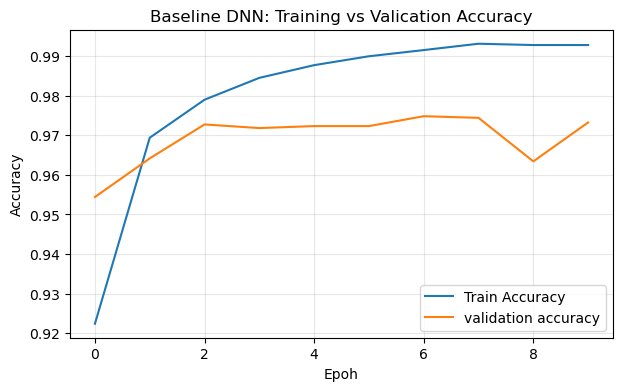

In [7]:
# Step 4: Evaluate on test set, report accuracy
# Plot training vs validation accuracy curves
# Randomly select 3 test images, display with true vs predicted labels
# YOUR CODE HERE
test_loss,test_acc=model.evaluate(x_test,y_test, verbose=0)
print(f"Baseline test loss:{test_loss:.4f}| test accuracy: {test_acc:.4f}")

plt.figure(figsize=(7,4))
plt.plot(history_base.history['accuracy'],label='Train Accuracy')
plt.plot(history_base.history['val_accuracy'],label='validation accuracy')
plt.xlabel('Epoh');plt.ylabel('Accuracy');plt.title('Baseline DNN: Training vs Valication Accuracy')
plt.legend(); plt.grid(alpha=0.3);plt.show()


Baseline test loss: 0.1200 | test accuracy: 0.9779


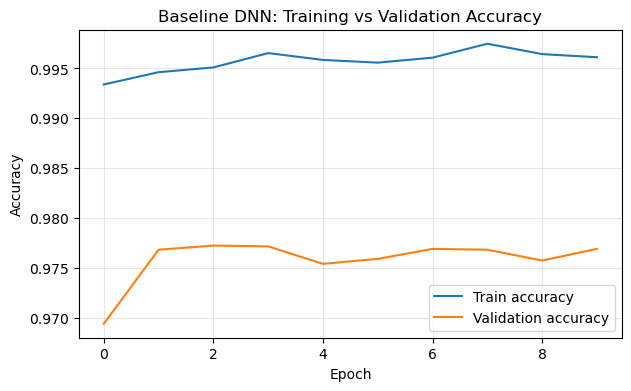

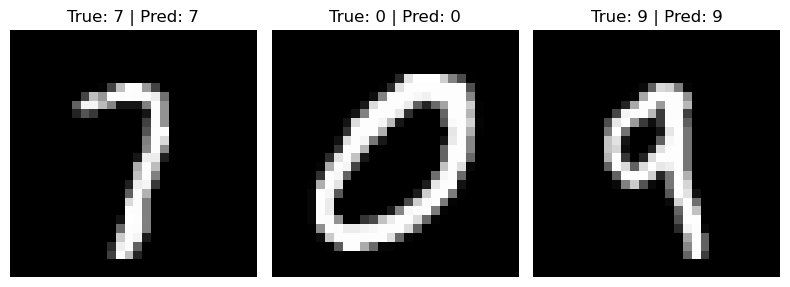

In [99]:
# Difficult
# Step 4: Evaluate on test set, report accuracy
# Plot training vs validation accuracy curves
# Randomly select 3 test images, display with true vs predicted labels
# YOUR CODE HERE

# test_loss: Measures prediction error on testing data. Lower is generally better.
# test_acc: Measures percentage of correct predictions. Higher is better.

test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0) # Test the Model
print(f"Baseline test loss: {test_loss:.4f} | test accuracy: {test_acc:.4f}")

# Plot training vs validation accuracy
plt.figure(figsize=(7,4))
# Accesses the training accuracy values stored inside the history_base object (which is returned by Keras's model.fit()).
#Plots these values as a line and assigns it the label 'Train accuracy' for the legend.

plt.plot(history_base.history['accuracy'], label='Train accuracy')
plt.plot(history_base.history['val_accuracy'], label='Validation accuracy')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.title('Baseline DNN: Training vs Validation Accuracy')
plt.legend(); plt.grid(alpha=0.3); plt.show()

# Randomly select 3 test images, show true vs predicted labels
idx = np.random.choice(len(x_test), 3, replace=False) #• andomly selects 3 unique indices from the test dataset (replace=False prevents picking the same image twice).

# model.predict(...) outputs probability scores for every class across the 3 selected images (verbose=0 hides the progress bar).
# np.argmax(..., axis=1) converts those probabilities into the single highest-scoring class index (the model's final prediction).
preds = np.argmax(model.predict(x_test[idx], verbose=0), axis=1)

plt.figure(figsize=(8,3))
for i, k in enumerate(idx):
    plt.subplot(1, 3, i+1)
    plt.imshow(x_test_img[k], cmap='gray')
    plt.title(f"True: {y_test_intlab[k]} | Pred: {preds[i]}") ## Called label from initial copy of test label
    plt.axis('off')
plt.tight_layout(); plt.show()

Test Loss: 0.0978 Test Accuracy: 0.9737


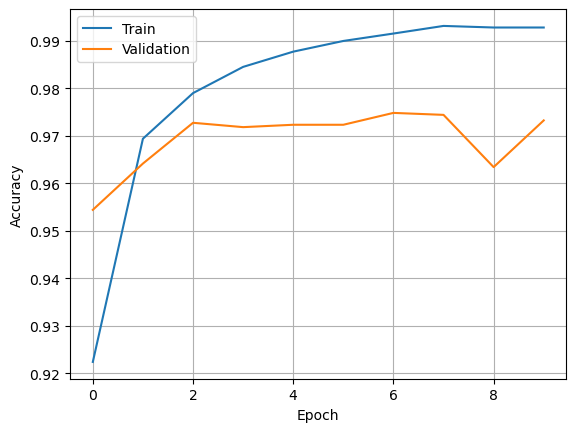

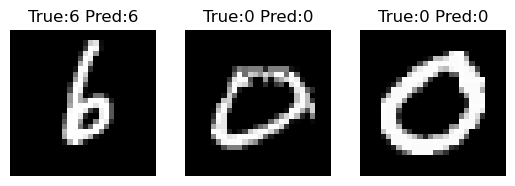

In [8]:
## Option 2: Simple code - # Step 4: Evaluate on test set, report accuracy

# 1. Evaluate model
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print("Test Loss:", round(test_loss, 4), "Test Accuracy:", round(test_acc, 4))

# 2. Plot accuracy
plt.plot(history_base.history['accuracy'], label='Train')
plt.plot(history_base.history['val_accuracy'], label='Validation')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

# 3. Predict 3 random images
idx = np.random.choice(len(x_test), 3, replace=False)
preds = np.argmax(model.predict(x_test[idx], verbose=0), axis=1)

# 4. Display images with actual and predicted labels
for i, k in enumerate(idx):
    plt.subplot(1, 3, i+1)
    plt.imshow(x_test_img[k], cmap='gray')
    plt.title(f"True:{y_test_intlab[k]} Pred:{preds[i]}")
    plt.axis('off')
plt.show()


---
#### Section B: Question 2 
Improve the baseline DNN from Q2 using **regularization and hyperparameter tuning** techniques.

**Mark Distribution:**
1. Add Dropout (0.3) after each hidden layer and retrain. Compare with Q2 baseline (5 marks)
2. Add Batch Normalization before each activation and retrain. Compare with Q2 and Dropout model (5 marks)
3. Experiment with learning rate: try lr=0.01, 0.001, 0.0001. Report which works best and why (5 marks)
4. Use EarlyStopping callback (patience=3). Train the best model configuration for up to 30 epochs. Report final test accuracy and justify which regularization technique helped the most (5 marks)


In [69]:
# Step 1: Add Dropout(0.3) after each hidden layer, retrain, compare
# YOUR CODE HERE
# Build DNN with Dropout
drop_model = Sequential([
    Dense(256, activation='relu', input_shape=(784,)), Dropout(0.3),
    Dense(128, activation='relu'), Dropout(0.3),
    Dense(64, activation='relu'), Dropout(0.3),
    Dense(10, activation='softmax')
])

drop_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
drop_model.fit(x_train, y_train, epochs=10, batch_size=64, validation_split=0.2)

print("Baseline:", model.evaluate(x_test, y_test, verbose=0)[1])
print("Dropout :", drop_model.evaluate(x_test, y_test, verbose=0)[1])


Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8564 - loss: 0.4735 - val_accuracy: 0.9538 - val_loss: 0.1552
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9420 - loss: 0.2115 - val_accuracy: 0.9664 - val_loss: 0.1166
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9551 - loss: 0.1597 - val_accuracy: 0.9681 - val_loss: 0.1028
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9620 - loss: 0.1320 - val_accuracy: 0.9741 - val_loss: 0.0937
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9677 - loss: 0.1132 - val_accuracy: 0.9732 - val_loss: 0.0967
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9705 - loss: 0.1029 - val_accuracy: 0.9758 - val_loss: 0.0883
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9731 - loss: 0.0923 - val_accuracy: 0.9748 - val_loss: 0.0948
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9749 - loss: 0.0838 - val_accuracy: 0.

In [70]:
# Step 2: Add BatchNormalization before activations, retrain, compare
# YOUR CODE HERE

# Build DNN with Batch Normalization
bn_model = Sequential([
    Dense(256, input_shape=(784,)), BatchNormalization(), Activation('relu'),
    Dense(128), BatchNormalization(), Activation('relu'),
    Dense(64), BatchNormalization(), Activation('relu'),
    Dense(10, activation='softmax')
])

bn_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
bn_model.fit(x_train, y_train, epochs=10, batch_size=64, validation_split=0.2)

print("Baseline :", model.evaluate(x_test, y_test, verbose=0)[1])
print("Dropout  :", drop_model.evaluate(x_test, y_test, verbose=0)[1])
print("BatchNorm:", bn_model.evaluate(x_test, y_test, verbose=0)[1])


Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.9313 - loss: 0.2471 - val_accuracy: 0.9653 - val_loss: 0.1151
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9705 - loss: 0.0967 - val_accuracy: 0.9657 - val_loss: 0.1156
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9793 - loss: 0.0662 - val_accuracy: 0.9722 - val_loss: 0.0920
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9833 - loss: 0.0521 - val_accuracy: 0.9745 - val_loss: 0.0806
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9864 - loss: 0.0415 - val_accuracy: 0.9762 - val_loss: 0.0783
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9888 - loss: 0.0335 - val_accuracy: 0.9763 - val_loss: 0.0806
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9902 - loss: 0.0308 - val_accuracy: 0.9773 - val_loss: 0.0824
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9912 - loss: 0.0248 - val_accuracy: 0.

In [73]:
# Step 3: Learning rate experiment (0.01, 0.001, 0.0001)
# Test different learning rates
for lr in [0.01, 0.001, 0.0001]:
    bn_model.compile(optimizer=Adam(learning_rate=lr), loss='categorical_crossentropy', metrics=['accuracy'])
    h = bn_model.fit(x_train, y_train, epochs=5, batch_size=64, validation_split=0.2, verbose=0)
    print("LR:", lr, "Accuracy:", max(h.history['val_accuracy']))



LR: 0.01 Accuracy: 0.9781666398048401
LR: 0.001 Accuracy: 0.9866666793823242
LR: 0.0001 Accuracy: 0.9864166378974915


In [75]:
# Step 4: EarlyStopping + best config, final evaluation
# YOUR CODE HERE
# EarlyStopping
bn_model.compile(optimizer=Adam(0.001),loss='categorical_crossentropy', metrics=['accuracy'])
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
bn_model.fit(x_train, y_train, epochs=30, batch_size=64, validation_split=0.2, callbacks=[early_stop])
print("Final Test Accuracy:", bn_model.evaluate(x_test, y_test, verbose=0)[1])


Epoch 1/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.9994 - loss: 0.0023 - val_accuracy: 0.9847 - val_loss: 0.0808
Epoch 2/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9992 - loss: 0.0023 - val_accuracy: 0.9862 - val_loss: 0.0827
Epoch 3/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9994 - loss: 0.0018 - val_accuracy: 0.9867 - val_loss: 0.0824
Epoch 4/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9992 - loss: 0.0023 - val_accuracy: 0.9865 - val_loss: 0.0859
Final Test Accuracy: 0.9864000082015991


In [ ]:
# Dropout reduces overfitting, Batch Normalization stabilizes training, and EarlyStopping prevents unnecessary training.

In [98]:
# tf.keras.models.Sequential??

---
## Section C: Reinforcement Learning (40 marks)

#### Section C: Question 1 (20 marks)
Implement **Q-Learning** on the FrozenLake-v1 environment (4×4 grid, is_slippery=False).

**Mark Distribution:**
1. Set up environment, define state/action spaces (3 marks)
2. Initialize Q-table, implement epsilon-greedy policy (5 marks)
3. Implement Q-learning update loop for 1000 episodes (5 marks)
4. Plot cumulative rewards, extract and display optimal policy grid (4 marks)
5. Analyze: what happens when gamma changes from 0.99 to 0.5? Run both and compare (3 marks)

In [77]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

In [78]:
# Step 1: Create FrozenLake-v1 environment (4x4, is_slippery=False)
# Print state space size and action space size
# YOUR CODE HERE
# Step 1: Create Environment
env = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=False)
n_states = env.observation_space.n
n_actions = env.action_space.n
print("States:", n_states, "Actions:", n_actions)

States: 16 Actions: 4


In [ ]:
# Step 2: Initialize Q-table (states x actions) with zeros
# Implement epsilon-greedy action selection function
# YOUR CODE HERE

In [ ]:
# Step 3: Q-Learning training loop
# Hyperparameters: alpha=0.1, gamma=0.99, epsilon=1.0, epsilon_decay=0.995, epsilon_min=0.01
# Run for 1000 episodes
# Track rewards per episode
# YOUR CODE HERE

In [ ]:
# Step 4: Plot cumulative rewards (moving average over 100 episodes)
# Extract optimal policy from Q-table: policy[s] = argmax_a Q(s,a)
# Display policy as a 4x4 grid with arrows (L/D/R/U)
# YOUR CODE HERE

In [ ]:
# Step 5: Repeat Q-Learning with gamma=0.5
# Compare: which gamma leads to better policy? Why?
# YOUR CODE HERE

Number of states: 16
Number of actions: 4
Success rate: 0.99


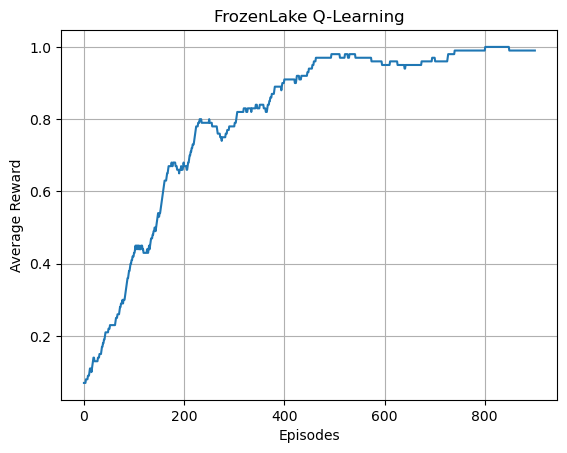

Optimal Policy:
[['→' '→' '↓' '←']
 ['↓' '←' '↓' '←']
 ['→' '→' '↓' '←']
 ['←' '↑' '→' '←']]
Success rate (last 100 episodes):
Gamma 0.99: 0.99
Gamma 0.50: 0.96


In [105]:

# Import required libraries
import gymnasium as gym          # Create and interact with RL environment
import numpy as np                # Perform numerical operations
import matplotlib.pyplot as plt   # Plot training rewards

# Step 1: Create FrozenLake Environment
env = gym.make("FrozenLake-v1", is_slippery=False)  # Create deterministic environment
n_states = env.observation_space.n                 # Get total number of states
n_actions = env.action_space.n                     # Get total number of actions

print("Number of states:", n_states)               # Display number of states
print("Number of actions:", n_actions)             # Display number of actions

# Step 2: Initialize Q-table and Epsilon-Greedy
Q = np.zeros((n_states, n_actions))  # Initialize Q-table with zeros

def choose_action(state, epsilon):   # Select action using epsilon-greedy
    if np.random.rand() < epsilon:   # Explore with probability epsilon
        return env.action_space.sample()  # Select random action
    return np.argmax(Q[state])       # Exploit the best-known action

# Step 3: Q-Learning Training (1000 Episodes)
alpha = 0.1          # Learning rate
gamma = 0.99         # Discount factor
epsilon = 1.0        # Initial exploration probability
epsilon_decay = 0.995  # Reduce exploration gradually
epsilon_min = 0.01   # Minimum exploration probability
episodes = 1000      # Total training episodes

Q = np.zeros((n_states, n_actions))  # Reset Q-table
rewards_per_episode = []             # Store reward of each episode

for ep in range(episodes):           # Repeat training for 1000 episodes
    state, _ = env.reset()           # Reset environment and get initial state
    done = False                     # Mark episode as not finished
    total_reward = 0                 # Initialize total episode reward

    while not done:                  # Continue until episode ends
        action = choose_action(state, epsilon)  # Select an action

        # Perform action and get next state, reward and termination status
        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated  # Check whether episode has ended

        # Update Q-value using Q-Learning formula
        Q[state, action] += alpha * (
            reward + gamma * np.max(Q[next_state]) - Q[state, action]
        )

        state = next_state            # Move to next state
        total_reward += reward        # Add reward to episode total

    rewards_per_episode.append(total_reward)  # Store episode reward
    epsilon = max(epsilon_min, epsilon * epsilon_decay)  # Reduce exploration

print("Success rate:", np.mean(rewards_per_episode[-100:]))  # Average last 100 rewards

# Step 4: Plot Rewards and Display Optimal Policy
window = 100  # Moving average window size

# Calculate average reward over every 100 episodes
moving_avg = np.convolve(
    rewards_per_episode, np.ones(window)/window, mode="valid"
)

plt.plot(moving_avg)                 # Plot moving average rewards
plt.title("FrozenLake Q-Learning")   # Set graph title
plt.xlabel("Episodes")               # Label X-axis
plt.ylabel("Average Reward")         # Label Y-axis
plt.grid()                           # Display grid
plt.show()                           # Show reward graph

arrows = ["←", "↓", "→", "↑"]       # Map actions to direction symbols

# Find best action for each state and arrange policy in 4x4 grid
policy = np.array([arrows[np.argmax(Q[s])]
                   for s in range(n_states)]).reshape(4, 4)

print("Optimal Policy:")             # Display optimal policy heading
print(policy)                        # Print best action for each state

# Step 5: Compare Gamma = 0.99 and 0.5
def train_q_learning(gamma):          # Train Q-learning for given gamma
    Q = np.zeros((n_states, n_actions))  # Initialize a new Q-table
    rewards = []                     # Store episode rewards
    epsilon = 1.0                    # Start with full exploration

    for ep in range(1000):            # Train for 1000 episodes
        state, _ = env.reset()        # Reset environment
        done = False                  # Episode is not finished
        total = 0                     # Initialize total reward

        while not done:               # Repeat until episode ends
            if np.random.rand() < epsilon:  # Check exploration probability
                action = env.action_space.sample()  # Select random action
            else:
                action = np.argmax(Q[state])  # Select best action

            ns, r, term, trunc, _ = env.step(action)  # Execute action
            done = term or trunc       # Check episode termination

            # Update Q-value using the given gamma
            Q[state, action] += 0.1 * (
                r + gamma * np.max(Q[ns]) - Q[state, action]
            )

            state = ns                 # Move to next state
            total += r                 # Add current reward

        rewards.append(total)          # Store episode reward
        epsilon = max(0.01, epsilon * 0.995)  # Decay exploration

    return Q, rewards                  # Return Q-table and rewards

# Train separately using two discount factors
Q_099, rewards_099 = train_q_learning(0.99)  # Train with gamma 0.99
Q_05, rewards_05 = train_q_learning(0.5)     # Train with gamma 0.50

print("Success rate (last 100 episodes):")  # Display comparison heading
print("Gamma 0.99:", np.mean(rewards_099[-100:]))  # Average success for 0.99
print("Gamma 0.50:", np.mean(rewards_05[-100:]))   # Average success for 0.50

env.close()  # Close the environment


Number of states: 16
Number of actions: 4
Success rate: 0.0


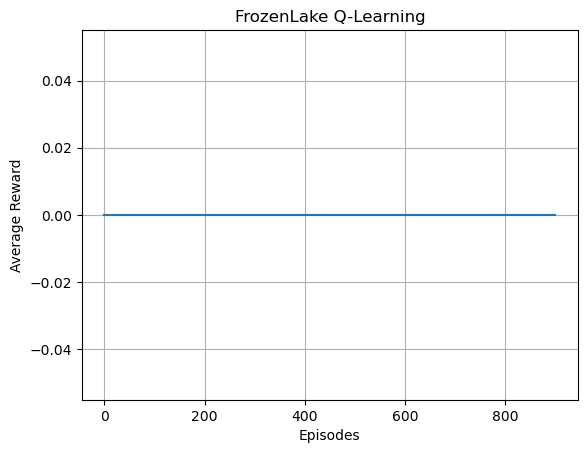

Optimal Policy:
[['←' '←' '←' '←']
 ['←' '←' '←' '←']
 ['←' '←' '←' '←']
 ['←' '←' '←' '←']]
Success rate (last 100 episodes):
Gamma 0.99: 0.0
Gamma 0.50: 0.0


In [106]:
# OPTION: 02
# Import Gymnasium to create and interact with the FrozenLake environment
import gymnasium as gym

# Import NumPy for numerical calculations and Q-table operations
import numpy as np

# Import Matplotlib for plotting the learning progress
import matplotlib.pyplot as plt


# ============================================================
# STEP 1: CREATE FROZENLAKE ENVIRONMENT
# ============================================================

# Create a 4x4 FrozenLake environment
# is_slippery=False means the agent moves in the selected direction
# without randomly slipping into another direction
env = gym.make("FrozenLake-v1", is_slippery=False)

# Get the total number of states (4x4 = 16 states)
n_states = env.observation_space.n

# Get the total number of possible actions (Left, Down, Right, Up)
n_actions = env.action_space.n

# Display the number of states and actions
print("Number of states:", n_states)
print("Number of actions:", n_actions)


# ============================================================
# STEP 2: INITIALIZE Q-TABLE AND EPSILON-GREEDY STRATEGY
# ============================================================

# Create a Q-table with 16 rows (states) and 4 columns (actions)
# Initially, all Q-values are zero
Q = np.zeros((n_states, n_actions))


# Define a function to select an action using epsilon-greedy strategy
def choose_action(state, epsilon):

    # Generate a random number between 0 and 1
    # If it is less than epsilon, select a random action (Exploration)
    if np.random.rand() < epsilon:
        return env.action_space.sample()

    # Otherwise, select the action with the highest Q-value (Exploitation)
    return np.argmax(Q[state])


# ============================================================
# STEP 3: Q-LEARNING TRAINING (1000 EPISODES)
# ============================================================

# Learning rate: controls how much new information is learned
alpha = 0.1

# Discount factor: determines the importance of future rewards
gamma = 0.99

# Initial exploration probability (100% exploration)
epsilon = 1.0

# Reduce exploration gradually after every episode
epsilon_decay = 0.995

# Minimum exploration probability (1%)
epsilon_min = 0.01

# Total number of training episodes
episodes = 1000

# Initialize Q-table again with zero values
Q = np.zeros((n_states, n_actions))

# Store the total reward obtained in each episode
rewards_per_episode = []


# Repeat training for 1000 episodes
for ep in range(episodes):

    # Reset the environment and get the starting state
    # The second returned value contains additional information
    state, _ = env.reset()

    # Initially, the episode is not finished
    done = False

    # Initialize total reward for the current episode
    total_reward = 0

    # Continue until the episode terminates or gets truncated
    while not done:

        # Select an action using epsilon-greedy strategy
        action = choose_action(state, epsilon)

        # Perform the selected action in the environment
        # ns = next state, reward = immediate reward
        # terminated = goal or hole reached
        # truncated = episode stopped due to a time limit
        next_state, reward, terminated, truncated, _ = env.step(action)

        # Episode ends if either terminated or truncated is True
        done = terminated or truncated

        # Update the Q-table using the Q-Learning formula
        # Old Q-value + Learning rate * Temporal Difference Error
        Q[state, action] += alpha * (
            reward + gamma * np.max(Q[next_state]) - Q[state, action]
        )

        # Move the agent to the next state
        state = next_state

        # Add the current reward to the episode's total reward
        total_reward += reward

    # Store the total reward obtained in this episode
    rewards_per_episode.append(total_reward)

    # Reduce epsilon to gradually move from exploration to exploitation
    # Keep epsilon at or above the minimum value of 0.01
    epsilon = max(epsilon_min, epsilon * epsilon_decay)


# Calculate average success rate over the last 100 episodes
# In FrozenLake, reward 1 means success and reward 0 means failure
print("Success rate:", np.mean(rewards_per_episode[-100:]))


# ============================================================
# STEP 4: PLOT REWARDS AND DISPLAY OPTIMAL POLICY
# ============================================================

# Define the moving average window size as 100 episodes
window = 100

# Calculate average reward over every 100 consecutive episodes
# np.ones(window)/window creates 100 equal weights
# mode="valid" returns only complete 100-episode averages
moving_avg = np.convolve(
    rewards_per_episode, np.ones(window)/window, mode="valid"
)

# Plot the moving average rewards
plt.plot(moving_avg)

# Add title to the graph
plt.title("FrozenLake Q-Learning")

# Label the X-axis
plt.xlabel("Episodes")

# Label the Y-axis
plt.ylabel("Average Reward")

# Display grid lines
plt.grid()

# Display the graph
plt.show()


# Define arrows representing the four possible actions
# Action 0 = Left, 1 = Down, 2 = Right, 3 = Up
arrows = ["←", "↓", "→", "↑"]

# Find the action with the highest Q-value for each state
# Convert the action number into its corresponding arrow
# Reshape the 16 states into a 4x4 FrozenLake grid
policy = np.array([
    arrows[np.argmax(Q[s])]

    for s in range(n_states)
]).reshape(4, 4)

# Display the learned optimal policy
print("Optimal Policy:")
print(policy)


# ============================================================
# STEP 5: COMPARE GAMMA = 0.99 AND GAMMA = 0.50
# ============================================================

# Define a function to train Q-Learning with a given gamma value
def train_q_learning(gamma):

    # Initialize a new Q-table with zero values
    Q = np.zeros((n_states, n_actions))

    # Create an empty list to store episode rewards
    rewards = []

    # Start with 100% exploration
    epsilon = 1.0

    # Train the agent for 1000 episodes
    for ep in range(1000):

        # Reset the environment and obtain the starting state
        state, _ = env.reset()

        # Initialize episode completion status
        done = False

        # Initialize total reward for this episode
        total = 0

        # Continue until the episode ends
        while not done:

            # Select a random action for exploration
            if np.random.rand() < epsilon:
                action = env.action_space.sample()

            # Otherwise, select the best-known action
            else:
                action = np.argmax(Q[state])

            # Execute action and obtain the next state and reward
            ns, r, term, trunc, _ = env.step(action)

            # Check whether the episode has ended
            done = term or trunc

            # Update Q-value using the Q-Learning formula
            Q[state, action] += 0.1 * (
                r + gamma * np.max(Q[ns]) - Q[state, action]
            )

            # Update current state to next state
            state = ns

            # Add reward to the episode's total reward
            total += r

        # Store the episode reward
        rewards.append(total)

        # Reduce exploration gradually, keeping minimum epsilon at 0.01
        epsilon = max(0.01, epsilon * 0.995)

    # Return the trained Q-table and episode rewards
    return Q, rewards


# Train the agent using gamma = 0.99 (higher future reward importance)
Q_099, rewards_099 = train_q_learning(0.99)

# Train the agent using gamma = 0.50 (lower future reward importance)
Q_05, rewards_05 = train_q_learning(0.5)


# Display the average success rate of the last 100 episodes
print("Success rate (last 100 episodes):")

# Calculate success rate for gamma = 0.99
print("Gamma 0.99:", np.mean(rewards_099[-100:]))

# Calculate success rate for gamma = 0.50
print("Gamma 0.50:", np.mean(rewards_05[-100:]))


# ============================================================
# STEP 6: CLOSE ENVIRONMENT
# ============================================================

# Release environment resources after training is completed
env.close()


---
#### Section C: Question 2 (20 marks)
Implement a **simple Deep Q-Network (DQN)** on CartPole-v1 using TensorFlow/Keras.

**Hyperparameters are provided below — you only need to write the core Q-Learning update logic.**

**Mark Distribution:**
1. Build a Q-Network: 1 hidden layer (32 neurons, ReLU) + output layer (2 neurons, linear). Compile with Adam(0.001) and MSE (5 marks)
2. Set up a simple replay buffer using `deque(maxlen=1000)`. Add helper function to sample random batch (5 marks)
3. Train DQN for 100 episodes: epsilon-greedy action selection, store experiences in buffer, train on random batches (5 marks)
4. Evaluate trained agent over 10 test episodes (greedy actions). Report avg reward. Plot training reward curve (5 marks)


In [108]:
import gymnasium as gym
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from collections import deque
import random
import matplotlib.pyplot as plt

In [109]:
# Step 1: Build Q-Network
# Input: state_size (4 for CartPole)
# Hidden: 2 layers with 64 neurons each, ReLU activation
# Output: action_size (2 for CartPole), linear activation
# Compile with Adam(lr=0.001) and MSE loss
# YOUR CODE HERE
# 1. Q-network: 4 state inputs, one hidden layer (32), 2 action outputs
env = gym.make("CartPole-v1")
state_size = env.observation_space.shape[0]
action_size = env.action_space.n

def build_q_network():
    model = Sequential([
        tf.keras.Input(shape=(state_size,)),
        Dense(32, activation="relu"),
        Dense(action_size, activation="linear")
    ])
    model.compile(optimizer=Adam(learning_rate=0.001), loss="mse")
    return model

q_network = build_q_network()
q_network.summary()

ValueError: Received an invalid value for `units`, expected a positive integer. Received: units=2

In [ ]:
# Step 2: Simple replay buffer using deque (5 marks)
from collections import deque
import random

# replay_buffer = deque(maxlen=1000)  # stores (state, action, reward, next_state, done)
# Helper: def sample_batch(buffer, batch_size=32): return random.sample(buffer, batch_size) if len(buffer)>=batch_size else None
# YOUR CODE HERE
# 2. Replay buffer and batch helper
replay_buffer = deque(maxlen=1000)

def sample_batch(buffer, batch_size=32):
    if len(buffer) < batch_size:
        return None
    return random.sample(buffer, batch_size)


In [ ]:
# Step 3: DQN Training loop for 100 episodes
# epsilon-greedy with decay: start=1.0, decay=0.995, min=0.01
# batch_size=32, gamma=0.99
# Train on mini-batches from replay buffer
# Track episode rewards
# YOUR CODE HERE
# 3. DQN training for 100 episodes
episodes = 100
batch_size = 32
gamma = 0.99
epsilon = 1.0
epsilon_decay = 0.995
epsilon_min = 0.01
episode_rewards = []

for episode in range(episodes):
    state, _ = env.reset(seed=episode)
    state = np.asarray(state, dtype=np.float32)
    total_reward = 0
    done = False

    while not done:
        if np.random.rand() <= epsilon:
            action = env.action_space.sample()
        else:
            action = int(np.argmax(q_network.predict(state.reshape(1, -1), verbose=0)[0]))

        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated
        next_state = np.asarray(next_state, dtype=np.float32)

        replay_buffer.append((state, action, reward, next_state, done))
        state = next_state
        total_reward += reward

        batch = sample_batch(replay_buffer, batch_size)
        if batch is not None:
            states = np.array([b[0] for b in batch])
            targets = q_network.predict(states, verbose=0)
            next_states = np.array([b[3] for b in batch])
            next_q = q_network.predict(next_states, verbose=0)
            for i, (s, a, r, ns, terminal) in enumerate(batch):
                targets[i, a] = r if terminal else r + gamma * np.max(next_q[i])
            q_network.train_on_batch(states, targets)

    episode_rewards.append(total_reward)
    epsilon = max(epsilon_min, epsilon * epsilon_decay)

env.close()
print("Training completed. Last 10 episode average:",
      np.mean(episode_rewards[-10:]))

In [ ]:
# Step 4: Evaluate trained agent over 10 episodes (epsilon=0, greedy)
# Report average reward
# Plot training reward curve
# YOUR CODE HERE
# 4. Evaluate over 10 episodes using greedy actions (epsilon=0)
test_env = gym.make("CartPole-v1")
test_rewards = []
for ep in range(10):
    state, _ = test_env.reset(seed=1000 + ep)
    state = np.asarray(state, dtype=np.float32)
    done = False
    total = 0
    while not done:
        action = int(np.argmax(q_network.predict(state.reshape(1, -1), verbose=0)[0]))
        state, reward, terminated, truncated, _ = test_env.step(action)
        state = np.asarray(state, dtype=np.float32)
        done = terminated or truncated
        total += reward
    test_rewards.append(total)
test_env.close()

print("10 evaluation rewards:", test_rewards)
print("Average evaluation reward:", np.mean(test_rewards))

plt.plot(episode_rewards)
plt.xlabel("Episode"); plt.ylabel("Total reward")
plt.title("DQN CartPole Training Rewards"); plt.show()

In [ ]:

import gymnasium as gym
import numpy as np
import random
import matplotlib.pyplot as plt
from collections import deque
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

# Step 1: Build Q-Network
env = gym.make("CartPole-v1")
model = Sequential([
    Dense(32, activation='relu', input_shape=(4,)),
    Dense(2, activation='linear')
])
model.compile(optimizer=Adam(0.001), loss='mse')

# Step 2: Replay Buffer
memory = deque(maxlen=1000)

def replay(batch_size=32):
    batch = random.sample(memory, batch_size)
    for s, a, r, ns, done in batch:
        target = r if done else r + 0.99 * np.max(model.predict(ns.reshape(1,4), verbose=0)[0])
        q = model.predict(s.reshape(1,4), verbose=0)
        q[0][a] = target
        model.train_on_batch(s.reshape(1,4), q)

# Step 3: Train DQN
rewards = []
epsilon = 1.0

for ep in range(100):
    state, _ = env.reset()
    total, done = 0, False

    while not done:
        if random.random() < epsilon:
            action = env.action_space.sample()
        else:
            action = np.argmax(model.predict(state.reshape(1,4), verbose=0)[0])

        ns, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated
        memory.append((state, action, reward, ns, done))
        state = ns
        total += reward

        if len(memory) >= 32:
            replay()

    rewards.append(total)
    epsilon = max(0.01, epsilon * 0.995)

env.close()

# Step 4: Evaluate for 10 episodes
test_env = gym.make("CartPole-v1")
test_rewards = []

for ep in range(10):
    state, _ = test_env.reset()
    total, done = 0, False

    while not done:
        action = np.argmax(model.predict(state.reshape(1,4), verbose=0)[0])
        state, reward, terminated, truncated, _ = test_env.step(action)
        done = terminated or truncated
        total += reward

    test_rewards.append(total)

test_env.close()

print("Average Test Reward:", np.mean(test_rewards))

plt.plot(rewards)
plt.xlabel("Episodes")
plt.ylabel("Total Reward")
plt.title("DQN Training Rewards")
plt.show()


C:\Users\Hp\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


DLRL – Detailed Study Notes: S1 to S9
Deep Learning and Reinforcement Learning | Chapter-wise detailed summary | ESA preparation

This version expands the earlier summary and follows the actual contents and sequence of the nine lecture sessions. It includes explanations, important subtopics, mathematical formulas, diagrams, examples, comparisons and practical concepts.

How to use these notes:
- Understand the concept first.
- Learn the highlighted definitions and formulas.
- Remember the differences in comparison tables.
- Practise the algorithms and Python concepts.
- Use the final revision section to prepare for ESA.
S1 – Introduction to Neural Networks
Deep Learning Fundamentals
Main topics covered in S1:
1. Introduction to Neural Networks.
2. Biological and Artificial Neurons.
3. Activation Functions.
4. Feedforward Neural Networks.
5. Layers in Neural Networks.
6. Training a Neural Network.
7. Error and Loss Functions.
8. Optimization and Gradient Descent.
9. Gradient Descent Variations.
10. Backpropagation.
11. Learning Rate and Momentum.
12. Introduction to TensorFlow and Keras.
1.1 Introduction to Artificial Neural Networks (ANN)
An Artificial Neural Network is a computing system inspired by the biological neural network of the human brain.

It consists of interconnected artificial neurons that process information and learn patterns from data.

Why do we use neural networks?
- To learn complex patterns from data.
- To perform classification and regression.
- To recognize images and speech.
- To predict future outcomes.
- To automate intelligent decision-making.
Examples:
- Face recognition.
- Handwritten digit recognition.
- Medical image classification.
- Fraud detection.
- Speech recognition.
1.2 Biological Neuron vs Artificial Neuron
A biological neuron receives signals, processes them and sends information to other neurons.

An artificial neuron performs a similar mathematical operation.








wasilzafar.com


Biological neuron	Artificial neuron
Dendrites	Inputs
Synapses	Weights
Cell body	Summation
Firing mechanism	Activation function
Axon	Output

Working of an artificial neuron:
1. Receives input values.
2. Multiplies inputs by weights.
3. Adds bias.
4. Applies activation function.
5. Produces output.
Mathematical formula:
\[
z=w_1x_1+w_2x_2+\cdots+w_nx_n+b
\]

\[
y=f(z)
\]

Where:
- \(x\) = Input.
- \(w\) = Weight.
- \(b\) = Bias.
- \(f\) = Activation function.
- \(y\) = Output.
Example:

Suppose:
- Input \(x_1=2\), \(x_2=3\)
- Weight \(w_1=0.5\), \(w_2=0.2\)
- Bias \(b=1\)
Then:
\[
z=(2\times0.5)+(3\times0.2)+1
\]

\[
z=2.6
\]

The activation function is applied to 2.6 to produce the final output.
1.3 Activation Functions
An activation function defines the output of a neuron when an input is provided.

It performs mathematical operations on the weighted input.

Why are activation functions required?

Without non-linear activation functions, multiple layers of a neural network would behave like a single linear transformation.

Non-linearity enables neural networks to learn complex decision boundaries.
A. Sigmoid Function
\[
f(x)=\frac{1}{1+e^{-x}}
\]









medium.com


Characteristics:
- S-shaped curve.
- Output ranges between 0 and 1.
- Historically popular.
- Useful for binary classification output probabilities.
Limitations:
1. Vanishing gradient problem.
2. Output is not zero-centred.
3. Slow convergence in some situations.
B. Tanh Function
\[
f(x)=\tanh(x)
\]









linkedin.com


Characteristics:
- Output ranges between -1 and +1.
- Zero-centred.
- Useful in some hidden-layer and recurrent-network applications.
- Can also suffer from vanishing gradients.
C. ReLU Function
\[
f(x)=\max(0,x)
\]









codesignal.com


Characteristics:
- Negative input produces zero.
- Positive input remains unchanged.
- Computationally simple.
- Commonly used in hidden layers.
Limitation: Some neurons may become permanently inactive (dying ReLU).
D. Binary Step Function
\[
f(x)=
\begin{cases}
0 & x<0\\
1 & x\geq0
\end{cases}
\]

Characteristics:
- Produces binary output.
- Uses a threshold.
- Not suitable for ordinary gradient-based training because its gradient is zero almost everywhere.
Activation Function Comparison
Function	Range	Main characteristics
Sigmoid	0 to 1	S-shaped
Tanh	-1 to +1	Zero-centred
ReLU	0 to infinity	Simple and fast
Binary Step	0 or 1	Threshold-based

1.4 Feedforward Neural Network
A Feedforward Neural Network is a neural network in which information travels in one direction.

Flow:

Input Layer → Hidden Layer → Output Layer








frontiersin.org


There are no feedback connections between layers.
Types of layers
1. Input Layer
- Receives the input data.
- Each node represents one input feature.
- Does not generally perform complex computation.
2. Hidden Layer
- Performs intermediate processing.
- Uses weights and biases.
- Applies activation functions.
- Extracts useful patterns.
3. Output Layer
- Produces the final prediction.
- Represents output classes or predicted numerical values.
Example
For handwritten digit classification:
- Input: 784 pixel values.
- Hidden layer: Learns image patterns.
- Output: 10 neurons representing digits 0–9.
1.5 Training a Neural Network
The lecture describes the following training procedure:
1. Decide the structure of the network.
2. Create the neural network.
3. Choose hyperparameters.
4. Calculate loss.
5. Reduce loss.
6. Repeat the optimization process.
The network learns suitable weights and biases during training.
Important training terms
Term	Meaning
Epoch	One complete pass through training data
Batch Size	Number of samples processed together
Iteration	One model update step
Weight	Strength of a connection
Bias	Additional adjustable parameter
Hyperparameter	Setting selected outside ordinary weight learning

1.6 Error and Loss Function
Error is the difference between actual output and predicted output.

A loss function measures this difference mathematically.
\[
Error=Actual-Predicted
\]

The main objective of training is to minimize loss.

Different loss functions are used for different problems.
Problem	Common loss function
Regression	Mean Squared Error
Binary classification	Binary Cross-Entropy
Multi-class classification	Categorical Cross-Entropy

Mean Squared Error
\[
MSE=\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat y_i)^2
\]

Where:
- \(y_i\) = Actual value.
- \(\hat y_i\) = Predicted value.
- n = Number of observations.
Example:

Actual value = 10, predicted value = 8.

Squared error:
\[
(10-8)^2=4
\]

1.7 Optimization
Optimization is the process of finding suitable weights that minimize the loss function.

The optimization algorithm adjusts weights repeatedly to improve prediction accuracy.

The lecture introduces gradient descent as the main optimization approach.
1.8 Gradient
A gradient represents how quickly the loss changes with respect to a parameter.

For a weight:
\[
Gradient=\frac{\partial L}{\partial w}
\]

Interpretation:
- Positive gradient: Increasing the weight increases loss locally.
- Negative gradient: Increasing the weight decreases loss locally.
- Zero gradient: The local slope is zero.
Weights are modified based on the calculated gradients.
1.9 Gradient Descent
Gradient Descent is an optimization algorithm that minimizes a cost or loss function by updating parameters in the opposite direction of the gradient.

Formula:
\[
w_{new}=w_{old}-\alpha\frac{\partial L}{\partial w}
\]

Where:
- \(w\) = Weight.
- \(\alpha\) = Learning rate.
- \(L\) = Loss function.








bradleyboehmke.github.io


Three types of Gradient Descent
1. Batch Gradient Descent
- Uses the complete training dataset.
- Calculates gradients using all training examples.
- Updates weights once per full dataset pass.
- Can be computationally expensive for large datasets.
2. Stochastic Gradient Descent (SGD)
- Uses one training example at a time.
- Updates weights after every example.
- Can be noisy but performs frequent updates.
3. Mini-Batch Gradient Descent
- Uses a small group of training examples.
- Combines advantages of Batch and Stochastic Gradient Descent.
- Commonly used in deep learning.
Feature	Batch GD	SGD	Mini-Batch GD
Data used	Entire dataset	One example	Small batch
Update frequency	Low	High	Medium
Computation	High per update	Low per update	Balanced
Training stability	Generally smooth	Noisy	Generally balanced

1.10 Backpropagation
Backpropagation is used to train feedforward neural networks.

It calculates the gradients of the loss function with respect to weights.

Main purpose: Minimize loss by updating network weights.








medium.com


Steps
1. Forward propagation calculates the predicted output.
2. Loss function calculates prediction error.
3. Backpropagation calculates gradients.
4. Gradients are propagated backwards through layers.
5. Weights and biases are updated.
6. Training repeats.
The chain rule of calculus is used to calculate gradients through multiple layers.
1.11 Learning Rate and Momentum
Learning Rate
Learning rate determines the size of each weight update.
Learning rate	Effect
Too small	Slow learning
Too large	Unstable updates or overshooting
Suitable	More effective convergence

Momentum
Momentum uses information from previous weight updates to influence the current update.

Benefits:
- Can speed up training.
- Can reduce oscillations.
- Can help move through shallow regions of the loss surface.
1.12 TensorFlow Introduction
The second part of S1 introduces TensorFlow.

TensorFlow is an open-source machine learning library developed by Google.

It is used for:
- Building neural networks.
- Training deep learning models.
- Numerical computation.
- Model evaluation.
- Model deployment.
Why TensorFlow?
1. Widely used deep learning framework.
2. Supports model development and deployment.
3. Industry support.
4. Works across servers, mobile devices and web platforms.
5. Supports GPU-based computation.
TensorFlow 2.x
The lecture introduces TensorFlow 2.x and its improvements over earlier TensorFlow versions.

Important concepts include:
- Eager execution.
- Improved usability.
- Integration with Keras.
- Simplified model development.
- TensorFlow APIs for training and deployment.
Keras
Keras is a high-level deep learning API that simplifies neural network development.

It provides easy-to-use components such as:
- Sequential models.
- Dense layers.
- Activation functions.
- Loss functions.
- Optimizers.
- Model training and evaluation.
Keras vs tf.keras
Keras	tf.keras
High-level neural network API	TensorFlow-integrated Keras API
Provides model-building abstractions	Provides TensorFlow integration
Simplifies model development	Supports TensorFlow-based training and deployment

S1 final takeaway: A neural network learns by performing forward propagation, calculating loss, propagating gradients backwards and updating weights using optimization.

Source: S1 PDF, pages 1–46, including the TensorFlow and Keras introduction. 
S1_Intoduction to NN.pptx.pdf

S2 – Building Blocks of Deep Learning
Neural Network Architecture
Main topics:
1. Neural network refresher.
2. Deep Neural Networks.
3. Forward propagation.
4. Vector calculus refresher.
5. Backpropagation.
6. Fully Connected Layers.
7. Activation Functions.
8. Softmax Function.
9. Cross-Entropy Loss.
2.1 Neural Network Refresher
A neural network consists of:
- Input layer.
- One or more hidden layers.
- Output layer.
Each hidden neuron has:
- Weights.
- Bias.
- Activation function.
A deep neural network contains multiple hidden layers.

Depth refers to the number of layers in the network.
2.2 Feedforward Through Multiple Layers
Feedforward is the process of calculating the expected output.

It combines:
- Input values.
- Weights.
- Biases.
- Activation functions.
For multiple layers:
\[
a^{(1)}=f(W^{(1)}x+b^{(1)})
\]

\[
a^{(2)}=f(W^{(2)}a^{(1)}+b^{(2)})
\]

The output of one layer becomes the input of the next layer.








asherbest.com


Composition of Functions
A deep neural network can be represented as a composition of mathematical functions.
\[
Output=f_3(f_2(f_1(x)))
\]

This means:
1. Input passes through the first function.
2. Its output passes through the second function.
3. The second output passes through the third function.
4. Final output is generated.
2.3 Fully Connected Layer
A Fully Connected Layer is also called a Dense Layer.

Every neuron in the current layer is connected to every neuron in the previous layer.








medium.com


Important points:
- Each connection has a weight.
- Each neuron has a bias.
- All inputs contribute to the weighted sum.
- Forward pass involves matrix multiplication, bias addition and activation.
Formula:
\[
Z=WX+b
\]

\[
A=f(Z)
\]

Example
If a layer has:
- 4 input neurons.
- 3 output neurons.
Number of weights:
\[
4\times3=12
\]

Number of biases:
\[
3
\]

Total trainable parameters:
\[
12+3=15
\]

2.4 Backpropagation – Detailed Explanation
Backpropagation is the method of calculating gradients for all network weights and biases.

The lecture emphasizes partial derivatives and the chain rule.
Why do we need backpropagation?
Predicted output is usually different from actual output.

The loss function measures this difference.

Backpropagation identifies how much each weight contributed to the loss.
Chain Rule
Suppose:
\[
y=f(u), \quad u=g(x)
\]

Then:
\[
\frac{dy}{dx}=
\frac{dy}{du}\times\frac{du}{dx}
\]

In a neural network, the same principle is applied through multiple layers.

For example:
\[
\frac{\partial L}{\partial w}
=
\frac{\partial L}{\partial y}
\times
\frac{\partial y}{\partial z}
\times
\frac{\partial z}{\partial w}
\]

This calculates the effect of an individual weight on total loss.
Backpropagation Process
Forward pass
Calculate prediction
Calculate loss
Calculate gradients using chain rule
Update weights and biases

2.5 Activation Functions
The lecture revisits activation functions and explains their importance.

An activation function:
- Takes a single input value.
- Applies a mathematical function.
- Introduces non-linearity.
- Determines the neuron's output.
Why Non-Linearity?
Without non-linearity, a multilayer network cannot learn sufficiently complex nonlinear relationships.

The most important functions are:
Activation	Formula	Use
Sigmoid	\(1/(1+e^{-x})\)	Binary output
Tanh	\(\tanh(x)\)	Zero-centred output
ReLU	\(\max(0,x)\)	Hidden layers

2.6 Softmax Function
Softmax converts a vector of raw scores into a probability distribution.

Formula:
\[
Softmax(z_i)=\frac{e^{z_i}}{\sum_j e^{z_j}}
\]

Properties:
1. Each output probability is between 0 and 1.
2. All probabilities add up to 1.
3. The highest probability represents the most likely class.
Example
Suppose the network predicts:
Class	Probability
Apple	0.70
Mango	0.20
Orange	0.10

The model predicts Apple.

Application: Multi-class classification.
2.7 Cross-Entropy Loss
Cross-Entropy Loss measures the difference between the actual class distribution and the predicted probability distribution.

Formula:
\[
L=-\sum_{i=1}^{C}y_i\log(\hat y_i)
\]

Where:
- C = Number of classes.
- y = Actual class label.
- \(\hat y\) = Predicted probability.
Example
Actual class = Apple.

Predicted probability of Apple = 0.9.

Loss:
\[
L=-\log(0.9)
\]

\[
L\approx0.105
\]

If the model predicts a very low probability for the correct class, loss becomes much higher.
Softmax vs Cross-Entropy
Softmax	Cross-Entropy
Converts scores into probabilities	Measures prediction error
Used in output layer	Used as loss function
Output sums to 1	Lower is better
Classification output	Classification training objective

2.8 Complete S2 Network
A complete classification network generally follows:

Input → Dense Layer → Activation → Dense Layer → Softmax → Cross-Entropy Loss → Backpropagation.

S2 final takeaway: Feedforward calculates predictions, Softmax generates class probabilities, Cross-Entropy calculates error and Backpropagation adjusts the network parameters.

Source: S2 Building Blocks PDF, 93 pages. S2_Building Blocks.pdf
 S2_Building Blocks.pdf


S3 – Fine Tuning Your Neural Network
Optimization and Regularization
Main topics:
1. Weight Initialization.
2. Vanishing Gradient.
3. Exploding Gradient.
4. Batch Normalization.
5. Dropout.
6. Data Preprocessing.
7. Data Augmentation.
8. Choosing Network Architecture.
9. Hyperparameter Optimization.
10. Learning Process Monitoring.
3.1 Why Fine-Tuning Is Required
After building a neural network, we must improve its performance.

A network may suffer from:
- Poor initialization.
- Slow training.
- Unstable gradients.
- Overfitting.
- Poor generalization.
- Incorrect architecture.
- Unsuitable hyperparameters.
Fine-tuning helps overcome these problems.
3.2 Weight Initialization
Weight initialization means assigning initial values to network weights before training.

The initial values affect how efficiently the network learns.
A. Zero Initialization
All weights are initialized to zero.

Problem:

All neurons in the same layer receive identical gradients and remain symmetric.

Therefore, they learn the same features.

The network cannot learn different representations effectively.
B. Random Initialization
Weights are initialized with random values.

Benefits:
- Breaks symmetry.
- Allows neurons to learn different features.
However, poorly chosen random values can cause vanishing or exploding gradients.
C. Xavier Initialization
Xavier initialization is used to maintain suitable variance of activations and gradients across layers.

It is commonly suitable for sigmoid and tanh-based networks.

A commonly used normal initialization is:
\[
W\sim N\left(0,\frac{2}{n_{in}+n_{out}}\right)
\]

The expression represents the variance.
D. He Initialization
He initialization is particularly suitable for ReLU activation.
\[
Var(W)=\frac{2}{n_{in}}
\]

It helps maintain the signal scale through layers using ReLU.
Comparison
Method	Purpose
Zero	Not suitable for ordinary hidden-layer learning
Random	Breaks symmetry
Xavier	Maintains activation variance
He	Designed for ReLU-type activations

3.3 Vanishing Gradient Problem
Vanishing gradient occurs when gradients become extremely small during backpropagation.








junwei-lu.github.io


Causes
- Deep networks.
- Repeated multiplication of small derivatives.
- Saturating activation functions such as sigmoid and tanh.
Effects
1. Earlier layers learn very slowly.
2. Weight updates become negligible.
3. Loss reduction becomes slow.
4. Training may effectively stop.
Solutions
- Appropriate weight initialization.
- ReLU-family activation functions.
- Batch normalization.
- LSTM or GRU for long sequences.
- Residual connections in suitable architectures.
3.4 Exploding Gradient Problem
Exploding gradients occur when gradients become excessively large during backpropagation.








medium.com


Effects
- Extremely large weight updates.
- Unstable training.
- Large fluctuations in loss.
- Numerical overflow in severe cases.
Solutions
- Gradient clipping.
- Appropriate initialization.
- Lower learning rate.
- Suitable network architecture.
- LSTM/GRU for recurrent sequence modelling.
Vanishing vs Exploding Gradient
Vanishing	Exploding
Gradient becomes very small	Gradient becomes very large
Learning becomes slow	Learning becomes unstable
Small weight updates	Excessively large updates
Earlier layers learn slowly	Weights fluctuate significantly

3.5 Regularization
Regularization is a technique used to prevent overfitting.
What is Overfitting?
Overfitting occurs when a model learns training data too closely, including noise and unnecessary details.

It performs well on training data but poorly on unseen data.








hellointerview.com


A. Batch Normalization
Batch Normalization normalizes activations within a mini-batch.

The lecture describes the objective as achieving normalized activations with approximately:
- Mean = 0.
- Standard deviation = 1.
Formula:
\[
\hat x=\frac{x-\mu_B}{\sqrt{\sigma_B^2+\epsilon}}
\]

Then scale and shift:
\[
y=\gamma\hat x+\beta
\]

Where:
- \(\mu_B\) = Batch mean.
- \(\sigma_B^2\) = Batch variance.
- \(\epsilon\) = Small constant.
- \(\gamma\) = Learnable scale.
- \(\beta\) = Learnable shift.
Benefits:
1. Improves training speed.
2. Helps stabilize the network.
3. Improves gradient flow.
4. Allows higher learning rates in many cases.
5. Reduces dependence on initialization.
6. Provides some regularization.
Training vs Testing:

During training, batch statistics are used.

During inference, running estimates of mean and variance are used instead of calculating fresh statistics from the current test batch.
B. Dropout
Dropout randomly sets selected neurons to zero during training.








width.ai


Why is dropout required?

In fully connected networks, neurons may develop excessive dependency on one another.

Dropout reduces this dependency and encourages redundant representations.

Benefits:
- Reduces overfitting.
- Prevents excessive neuron dependency.
- Improves generalization.
During testing:

All neurons are enabled.

The activations are appropriately scaled, or equivalently handled using inverted dropout during training.
Batch Normalization vs Dropout
Batch Normalization	Dropout
Normalizes activations	Randomly disables neurons
Stabilizes training	Reduces overfitting
Uses batch statistics during training	Uses random masking during training
Uses running statistics at testing	All neurons are active at testing

3.6 Data Preprocessing
Data preprocessing prepares raw data for neural network training.

Common operations:
- Handling missing values.
- Removing duplicates.
- Encoding categorical values.
- Scaling numerical features.
- Normalizing image values.
- Splitting training and testing data.
Example: MNIST images contain pixel values from 0 to 255.

Normalization:
\[
X_{normalized}=\frac{X}{255}
\]

This converts values into the range 0–1.
3.7 Data Augmentation
Data augmentation artificially increases training data diversity by applying transformations to existing data.

Image augmentation examples:
- Rotation.
- Flipping.
- Zooming.
- Shifting.
- Cropping.
Benefits:
- Increases data variety.
- Reduces overfitting.
- Improves generalization.
3.8 Choosing the Right Architecture
Architecture means the design of the neural network.

Important decisions:
1. Number of hidden layers.
2. Number of neurons per layer.
3. Activation functions.
4. Regularization.
5. Output layer design.
The lecture uses MNIST as an example:
- Input: 784 pixel values.
- Output: 10 neurons, one for each digit class.
3.9 Hyperparameter Optimization
Hyperparameters control the learning process.

Important hyperparameters:
Hyperparameter	Purpose
Learning Rate	Controls update size
Batch Size	Controls samples per update
Epochs	Controls complete dataset passes
Number of Layers	Controls network depth
Neurons	Controls layer capacity
Dropout Rate	Controls dropout strength
L2 Regularization	Penalizes large weights

Grid Search
Tests all specified combinations of hyperparameters.
Random Search
Tests randomly selected combinations.
Early Stopping
Stops training when validation performance stops improving.

Example:
- Monitor validation loss.
- Patience = 3.
- Stop if validation loss does not improve for three consecutive epochs.
- Restore best weights.
S3 final takeaway: Fine-tuning improves training stability, prevents overfitting and helps a neural network generalize to unseen data.

Source: S3 Fine Tuning Your Neural Network PDF, 37 pages. 
S3_Fine Tuning your Neural Network.pdf

S4 – Recurrent Neural Networks and Time Series Forecasting
Sequential Data and Forecasting
S4 consists of two separate lecture PDFs:
- S4A – Recurrent Neural Network.
- S4B – Working with Time Series Data.
These are related subjects, but their concepts and algorithms are different.
S4A – Recurrent Neural Network (RNN)
4.1 Introduction to Sequential Data
Sequential data is data in which the order of observations is important.

The lecture discusses the following examples.
Type	Example	Application
Text	Sentences and words	Language translation
Time Series	Stock prices and sales	Forecasting
Audio	Speech signals	Speech recognition
Video	Consecutive frames	Action recognition
Biological	DNA and protein sequences	Bioinformatics

Why is sequence order important?
Consider:
- The cat chased the mouse.
- The mouse chased the cat.
Both sentences contain the same words, but the order changes the meaning.

This is why sequential data requires models that can understand relationships between previous and current observations.
4.2 Characteristics of Sequential Data
The lecture explains three important characteristics.

1. Sequence Structure

The position of each element determines its meaning.

2. Temporal Relationships

A current observation may depend on previous observations.

There are two types:
- Short-term dependency: Information from nearby observations.
- Long-term dependency: Information from observations far back in the sequence.
3. Variable Length

Sequences can have different lengths.

Examples:
- Short and long sentences.
- Different audio recording durations.
- Different time series lengths.
This creates challenges when processing sequences in batches.
4.3 Why Feedforward Networks Are Inadequate
Feedforward networks process inputs independently.

They do not have built-in memory of previous observations.

For example, predicting tomorrow's temperature may require previous days' temperature readings.

A normal feedforward network does not naturally retain this historical information.

Solution: RNN.
4.4 Concept of Memory in a Model
Memory allows a model to store information from previous inputs.

The network maintains an internal state.

At every time step:
1. Receives current input.
2. Combines it with previous hidden state.
3. Updates internal memory.
4. Produces output.
This allows the model to learn sequential patterns.
4.5 Other Approaches to Sequence Modelling
Your lecture briefly introduces different methods.
Method	Description	Limitation / Feature
Autoregressive Model	Uses previous observations to predict the next	Fixed history window
Feedforward Network	Uses nonlinear hidden layers for prediction	Limited memory
Linear Dynamical System	Uses continuous hidden state	State is not directly observed
Hidden Markov Model	Uses discrete hidden states and transition probabilities	Requires inference over hidden states
RNN	Updates hidden state nonlinearly	Learns sequential dependencies

4.6 What is RNN?
RNN stands for Recurrent Neural Network.

It is a neural network with feedback connections.

It processes sequential data one time step at a time and maintains information through a hidden state.








yganalyst.github.io


Main components
Component	Meaning
Input (X)	Current input
Hidden State (S or h)	Memory
Output (O or y)	Prediction
U	Input-to-hidden weights
W	Hidden-to-hidden recurrent weights
V	Hidden-to-output weights

These weights are learned during training.
4.7 RNN Working
Suppose the input sequence is:
Input 1
Input 2
Input 3


Hidden 1
Hidden 2
Hidden 3

Hidden states pass information forward through time.

At time step t, the output depends on:
1. Current input.
2. Previous hidden state.
RNN Forward Equations
Hidden state:
\[
h_t=\tanh(Ux_t+Wh_{t-1}+b_h)
\]

Output:
\[
y_t=Vh_t+b_y
\]

Where:
- \(x_t\) = Current input.
- \(h_{t-1}\) = Previous hidden state.
- \(h_t\) = Current hidden state.
- U, W, V = Weight matrices.
- b = Bias.
The same weight matrices are reused at every time step. This is called weight sharing.
4.8 RNN Unfolding
RNN unfolding or unrolling means representing a recurrent network as a sequence of repeated cells over time.

For example:
- Cell 1 processes input at t=1.
- Cell 2 processes input at t=2.
- Cell 3 processes input at t=3.
All these cells share the same weights.

Unfolding helps us understand how information travels through time and how BPTT works.
4.9 Backpropagation Through Time (BPTT)
BPTT is the training method used for RNNs.

It calculates gradients by propagating errors backwards across time steps.
Steps
1. Unfold the RNN across time.
2. Perform forward propagation.
3. Calculate loss.
4. Start from the last time step.
5. Propagate gradients backwards through time.
6. Calculate weight gradients.
7. Update shared weights.
The lecture also includes the equations:
\[
h_t=\tanh(W_{xh}x_t+W_{hh}h_{t-1}+b_h)
\]

\[
y_t=W_{hy}h_t+b_y
\]

\[
L=\sum_t L_t
\]

Total sequence loss is accumulated across time steps.
4.10 Vanishing and Exploding Gradients in RNN
As the sequence becomes longer, the gradient is propagated through many time steps.

This can cause two problems.

Vanishing Gradient:
- Gradient becomes very small.
- Earlier time steps receive almost no learning signal.
- Long-term dependencies are difficult to learn.
Exploding Gradient:
- Gradient becomes very large.
- Weight updates become unstable.
- Training may diverge.
Example from the lecture
The lecture uses the idea of a cue word separated from the prediction by multiple units.
- Short dependency: "sky → clouds".
- Longer dependency: "Hindi → India".
As the distance increases, remembering the relevant earlier information becomes difficult for a basic RNN.
4.11 RNN Extensions
Two extensions mentioned in the lecture:

Bidirectional RNN

Processes information in both forward and backward directions.

Deep Bidirectional RNN

Uses multiple recurrent layers while processing information in both directions.
RNN Applications
- Sentiment analysis.
- Machine translation.
- Text generation.
- Speech recognition.
- Time series forecasting.
- Video analysis.
S4A takeaway: RNN is designed for sequential data by maintaining a hidden state. BPTT trains the network, but long sequences create vanishing and exploding gradient problems.

S4_ Recurrent Neural Network   (1).pdf
 S4_ Recurrent Neural Network   (1).pdf


S4B – Working with Time Series Data
This lecture focuses on understanding historical observations and predicting future values.
4.12 What is Time Series Data?
Time series is a sequence of observations recorded over time.

Examples:
- Daily stock prices.
- Hourly temperature.
- Monthly sales.
- Quarterly revenue.
- Annual production.
Mathematical representation:
\[
X=\{x_1,x_2,x_3,\ldots,x_T\}
\]

Where:
- \(x_t\) = Observation at time t.
- T = Total observations.
Important: The order of observations is important.

Unlike ordinary tabular data, randomly changing the order can destroy meaningful temporal information.
4.13 Scope of Time Series Forecasting
Your lecture covers:
1. Understanding time series data.
2. Important features of time series.
3. Time series exploratory data analysis.
4. Smoothing techniques.
5. ARMA processes.
6. ARIMA for non-stationary and seasonal series.
7. Multivariate time series forecasting.
4.14 Missing Values in Time Series
The lecture emphasizes that observations should be contiguous.

Missing values should be imputed using an appropriate method.

Common methods:
- Forward fill.
- Backward fill.
- Linear interpolation.
- Mean or median imputation where appropriate.
- Domain-based estimation.
Example:
Month	Sales
January	100
February	Missing
March	140

Linear interpolation gives:
\[
February=\frac{100+140}{2}=120
\]

4.15 Time Series Exploratory Data Analysis (EDA)
The first step is plotting the time series.

Why?

A graph helps identify:
- Trends.
- Seasonality.
- Unusual observations.
- Sudden spikes.
- Sudden drops.
- Changes in data levels.
- Relationships between multiple series.








medium.com


4.16 Components of Time Series
The lecture identifies three components.








faridjb.github.io


A. Trend
Trend is the long-term movement of a time series.

It may be:
- Increasing.
- Decreasing.
- Approximately constant.
Example: Sales increasing over five years.
B. Seasonality
Seasonality represents stable, repeating fluctuations at regular intervals.

Examples:
- Higher sales during festivals.
- Increased demand for winter clothes.
- Increased travel demand during holidays.
- Seasonal disease patterns.
The lecture explains that a yearly series does not have intra-year seasonality in the same sense as monthly or quarterly observations.

Quarterly example:

Suppose annual sales are 400 units.

Quarterly average:
\[
400/4=100
\]

Actual sales:
Quarter	Sales	Seasonal difference
Q1	80	-20
Q2	70	-30
Q3	200	+100
Q4	50	-50

This shows the seasonal effect in each quarter.
C. Irregular Component
Irregular component is the random variation that cannot be explained by systematic patterns.

Other names:
- Error.
- Residual.
- White Noise.
The lecture assumes this random component has:
- Mean approximately zero.
- Constant variance.
Summary of components
Component	Nature	Example
Trend	Long-term systematic	Sales growth
Seasonality	Repeated systematic	Festival demand
Irregular	Random	Unexpected event

4.17 Systematic and Irregular Components
Systematic component:
- Trend.
- Seasonality.
- Interpretable patterns.
- Can be estimated.
Irregular component:
- Random fluctuations.
- Cannot be explained by systematic patterns.
- Represents unexplained variation.
Forecasting involves estimating systematic patterns and extrapolating them into the future.
4.18 Time Series Decomposition
Decomposition separates a time series into components.

It helps us understand:
- Long-term movement.
- Seasonal effects.
- Random variation.
- Underlying revenue or demand patterns.
Why decomposition?
1. Remove seasonal effects.
2. Understand long-term trends.
3. Compare different periods.
4. Compare industries with different seasonal patterns.
5. Understand which component has a greater influence.
A. Additive Model
\[
Y=T+S+I
\]

Where:
- Y = Observed series.
- T = Trend.
- S = Seasonal component.
- I = Irregular component.
When to use:

Seasonal fluctuations remain approximately constant in magnitude as the trend changes.

Example: Average monthly temperature.

An important property of additive seasonal indices is that they sum to zero over a complete seasonal cycle.
B. Multiplicative Model
\[
Y=T\times S\times I
\]

When to use:

Seasonal fluctuations change proportionally with the level of the series.

Example: Passenger volume increasing over time with larger seasonal fluctuations as overall volume grows.
Additive vs Multiplicative
Additive	Multiplicative
Components are added	Components are multiplied
Seasonal variation is approximately constant	Seasonal variation changes with level
Used when seasonal amplitude is stable	Used when seasonal amplitude grows or shrinks
Seasonal indices sum to zero	Seasonal factors average around one

4.19 Moving Average
Moving Average is a smoothing technique used to reduce short-term fluctuations.

It helps identify the underlying trend.

Formula for a simple moving average:
\[
MA_t=\frac{X_t+X_{t-1}+\cdots+X_{t-n+1}}{n}
\]

Example:

Values: 10, 20, 30.

Three-period moving average:
\[
MA=\frac{10+20+30}{3}=20
\]

Benefits:
- Smooths noisy data.
- Helps identify trends.
- Makes patterns easier to observe.
4.20 Stationarity
A stationary time series has statistical properties that remain stable over time.

Important properties:
1. Constant mean.
2. Constant variance.
3. Autocovariance depends on lag, not absolute time.
A time series containing a changing trend or variance may be non-stationary.

Stationarity is important for traditional ARMA and ARIMA modelling.
4.21 AR, MA, ARMA and ARIMA
These are important time series models in the lecture's stated syllabus.
Model	Full form	Main concept
AR	AutoRegressive	Uses previous observations
MA	Moving Average	Uses previous forecast errors
ARMA	AutoRegressive Moving Average	Combines AR and MA
ARIMA	AutoRegressive Integrated Moving Average	Adds differencing for non-stationarity

A. AR Model
Uses past observations to predict the current value.
\[
X_t=c+\phi_1X_{t-1}+\epsilon_t
\]

B. MA Model
Uses past error terms to predict the current value.
\[
X_t=\mu+\epsilon_t+\theta_1\epsilon_{t-1}
\]

C. ARMA Model
Combines autoregressive and moving-average components.

Used for stationary time series.
D. ARIMA Model
ARIMA includes differencing to make a non-stationary series more suitable for modelling.

Its parameters are:
\[
ARIMA(p,d,q)
\]

Where:
- p = AR order.
- d = Differencing order.
- q = MA order.
4.22 Univariate vs Multivariate Time Series
Univariate	Multivariate
One variable over time	Multiple variables over time
Example: Monthly sales	Sales, price and advertising
Simpler analysis	Captures relationships between variables

4.23 Time Series Forecasting with RNN
The RNN lecture also connects sequential learning with time series forecasting.
Sliding Window Technique
Sliding windows convert time series observations into supervised learning samples.

Example:

Original series:

10, 20, 30, 40, 50, 60

Window size = 3.
Input	Target
10, 20, 30	40
20, 30, 40	50
30, 40, 50	60

The model learns to predict the next observation from previous observations.
Train-Test Split
Time series must be split chronologically.

Example:
- Training: First 70%.
- Validation: Next 15%.
- Testing: Last 15%.
Random shuffling should generally be avoided because it can leak future information into training.

S4B takeaway: Time series analysis studies trend, seasonality and irregular variation. Decomposition, moving averages and ARIMA are important forecasting techniques.

S4_Working with time series data.pptx.pdf
 S4_Working with time series data.pptx.pdf


S5 – LSTM Networks
Advanced Recurrent Neural Networks
Main topics:
1. Motivation for LSTM.
2. Limitations of traditional RNN.
3. LSTM architecture.
4. Cell State.
5. Hidden State.
6. Forget Gate.
7. Input Gate.
8. Output Gate.
9. GRU.
10. LSTM vs GRU vs RNN.
5.1 What is LSTM?
LSTM stands for Long Short-Term Memory.

It is a special type of Recurrent Neural Network designed to learn long-term dependencies in sequential data.

It controls information flow using gates.
5.2 Why LSTM is Required
Traditional RNN has difficulty remembering information over long sequences.

During backpropagation, it suffers from:
- Vanishing gradients.
- Exploding gradients.
For example, consider a long paragraph.

The important information may appear at the beginning, while the prediction is required at the end.

A basic RNN may lose the important earlier information.

LSTM addresses this problem using memory cells and gating mechanisms.
5.3 LSTM Architecture








sharangkulkarni-fatherson.medium.com


The two important memory components are:
1. Cell State.
2. Hidden State.
5.4 Cell State
Cell state represents long-term memory.

It carries important information from earlier time steps to later time steps.

The lecture describes it as a conveyor belt running through the LSTM cell.

Its purpose is to help information flow across long sequences with reduced gradient deterioration.
5.5 Hidden State
Hidden state represents the current output or short-term representation.

It passes information to the next time step and contributes to the prediction.
Cell State vs Hidden State
Cell State	Hidden State
Long-term memory	Short-term representation
Carries important information	Represents current information
Controlled through gates	Passed to next recurrent step
Helps retain long-term dependencies	Helps generate output

5.6 Three LSTM Gates
The LSTM architecture contains three gates.








mdpi.com


A. Forget Gate
The Forget Gate decides how much previous information should be removed from the cell state.

Question it answers: What should I forget?

Its output ranges between 0 and 1.
- 0 means forget completely.
- 1 means retain completely.
Formula:
\[
f_t=\sigma(W_f[h_{t-1},x_t]+b_f)
\]

B. Input Gate
The Input Gate decides how much new information should be stored.

Question it answers: What new information should I remember?

It uses:
- Sigmoid function to decide what to update.
- Tanh function to create candidate information.
Formulas:
\[
i_t=\sigma(W_i[h_{t-1},x_t]+b_i)
\]

\[
\tilde C_t=\tanh(W_C[h_{t-1},x_t]+b_C)
\]

C. Output Gate
The Output Gate decides how much information should be passed to the output.

Question it answers: What information should I show?

Formula:
\[
o_t=\sigma(W_o[h_{t-1},x_t]+b_o)
\]

Cell State Update
\[
C_t=f_tC_{t-1}+i_t\tilde C_t
\]

Hidden State Update
\[
h_t=o_t\tanh(C_t)
\]

These equations show how the three gates control memory and output.
5.7 Complete LSTM Working
1. Forget Gate decides which old information to remove.
2. Input Gate decides which new information to store.
3. Cell State is updated.
4. Output Gate determines the current output.
5. Updated hidden state is passed to the next time step.
Easy way to remember
Gate	Remember
Forget	Remove old information
Input	Store new information
Output	Pass information forward

5.8 GRU – Gated Recurrent Unit
GRU is another gated recurrent network and is a simplified alternative to LSTM.

The lecture describes GRU as a newer, simpler RNN architecture.
GRU characteristics
- Does not contain a separate cell state.
- Uses hidden state to transport information.
- Contains two gates.
- Generally has fewer operations.
- Often trains faster than LSTM.
5.9 Two GRU Gates








ml-cheatsheet.readthedocs.io


A. Update Gate
The Update Gate combines the functions of the Forget and Input Gates.

It controls:
- How much previous information is retained.
- How much new information is incorporated.
B. Reset Gate
The Reset Gate controls how much past information should be ignored while generating candidate information.

It determines the influence of previous hidden state.
5.10 RNN vs LSTM vs GRU
Feature	RNN	LSTM	GRU
Memory	Hidden state	Cell + hidden state	Hidden state
Gates	No gating	3 gates	2 gates
Long-term memory	Limited	Good	Good
Architecture	Simple	Complex	Simpler
Computation	Lower	Higher	Generally lower than LSTM
Long sequences	Difficult	Suitable	Suitable

Important exam points:
1. LSTM is a variant of RNN.
2. LSTM helps learn long-term dependencies.
3. Cell state represents long-term memory.
4. Hidden state represents current output information.
5. LSTM contains three gates.
6. GRU contains two gates.
7. GRU has no separate cell state.
S5 takeaway: LSTM and GRU improve traditional RNN by controlling information flow through gates and maintaining useful memory over long sequences.
S5_ LSTM Networks.pdf

S6 – Foundations of Reinforcement Learning
Reinforcement Learning Fundamentals
Main topics:
1. Introduction to Reinforcement Learning.
2. Supervised vs Unsupervised vs Reinforcement Learning.
3. Elements of RL.
4. Agent-Environment Loop.
5. State, Action and Reward.
6. Policy and Model.
7. Return and Discount Factor.
8. Exploration and Exploitation.
9. Applications.
10. Advantages and Limitations.
6.1 What is Reinforcement Learning?
Reinforcement Learning is a machine learning technique in which an agent learns through interaction with an environment.

It receives feedback in the form of rewards or penalties.

The objective is to maximize cumulative reward.
Example
A robot learns to walk:
- Correct movement: Positive reward.
- Falling: Negative reward.
- Repeated trials: Improves movement strategy.








amr-ae.com


6.2 Types of Machine Learning
Supervised Learning	Unsupervised Learning	Reinforcement Learning
Uses labelled data	Uses unlabelled data	Learns by interaction
Correct output available	No target labels	Rewards and penalties
Classification	Clustering	Decision-making
Regression	Pattern discovery	Robotics and games

6.3 Main Elements of Reinforcement Learning
A. Agent
The agent is the learner or decision maker.

Examples:
- Robot.
- Chess-playing AI.
- Self-driving car controller.
- Trading algorithm.
The agent observes the environment and decides what action to take.
B. Environment
Environment is everything external to the agent.

Examples:
- Physical world.
- Chessboard.
- Road conditions.
- Financial market.
- CartPole simulation.
The environment:
- Maintains current state.
- Responds to actions.
- Produces rewards.
- Determines state transitions.
C. State
State contains information about the current situation.

Example: In a chess game, the board position represents the current state.
D. Action
Action is the decision taken by the agent.

Examples:
- Move left.
- Move right.
- Jump.
- Accelerate.
- Stop.
E. Reward
Reward is a numerical feedback signal.

The objective is to maximize rewards.

Examples:
Situation	Reward
Reaching goal	+10
Correct action	+1
Falling	-10
Wrong direction	-1

F. Episode
An episode is one complete sequence of interaction, generally ending at a terminal state.

Example: One complete game of chess or one CartPole trial.
G. Policy
Policy is the strategy followed by the agent to choose actions.

Two types:

Deterministic policy:
\[
a=\pi(s)
\]

The same state produces the same action.

Stochastic policy:
\[
a\sim\pi(\cdot|s)
\]

Actions are selected according to probabilities.
H. Model
A model represents how the environment behaves.

It can predict:
- Next state.
- Immediate reward.
A model can help the agent plan future actions.
6.4 Agent-Environment Loop
Agent observes state
Select action using policy
Environment executes action
Receive reward and next state
Learn and improve policy
Repeat until the objective is achieved or episode ends.
6.5 Return
Return represents cumulative future rewards.

Formula:
\[
G_t=r_{t+1}+\gamma r_{t+2}+
\gamma^2r_{t+3}+\cdots
\]

It represents the total discounted reward from time t onwards.
Example
Suppose:
- First reward = 10.
- Second reward = 5.
- Third reward = 2.
- Discount factor = 0.9.
Then:
\[
G=10+(0.9\times5)+(0.9^2\times2)
\]

\[
G=16.12
\]

6.6 Discount Factor
Discount factor is represented by gamma.
\[
0\leq\gamma\leq1
\]

Gamma	Meaning
0	Only immediate reward matters
0.5	Future rewards are discounted considerably
0.9	Future rewards remain important
1	Future rewards are not discounted

6.7 Exploration vs Exploitation
Exploration
Trying new actions to discover better possibilities.
Exploitation
Choosing the best-known action based on existing knowledge.

Example: Restaurant selection.
- Exploration: Trying a new restaurant.
- Exploitation: Visiting the restaurant already known to be good.
Exploration	Exploitation
Tries new actions	Uses known best actions
Learns new information	Maximizes known reward
May initially receive lower reward	Uses existing knowledge
Reduces uncertainty	Uses learned estimates

6.8 Applications of Reinforcement Learning
Area	Application
Robotics	Walking and object manipulation
Gaming	Chess, Go and Atari
Autonomous vehicles	Driving decisions
NLP	Chatbots and translation optimization
Manufacturing	Industrial automation
Education	Adaptive learning
E-commerce	Recommendation systems
Telecom	Network resource allocation

6.9 Advantages of RL
1. Solves complex decision-making problems.
2. Learns from direct interaction.
3. Handles uncertain environments.
4. Can improve its behaviour through feedback.
5. Can be combined with deep learning.
6. Useful in control and optimization.
6.10 Limitations of RL
1. Requires considerable data and computation.
2. Training can be time-consuming.
3. Reward function must be carefully designed.
4. Difficult to debug and interpret.
5. Does not guarantee maximum possible reward.
6. Not necessary for simple problems.
S6 takeaway: RL is based on the agent learning through actions, receiving rewards and improving its policy to maximize long-term rewards.
S6_Foundations of Reinforcement Learning  (3).pdf

S6 – Part B: Introduction to OpenAI Gym and Stable Baselines
This is the second PDF under S6.
6.11 What is OpenAI Gym?
OpenAI Gym is a standard API and collection of simulated environments for reinforcement learning.

It allows an agent to interact with different simulated problems.

Why do we need Gym?

In real-world applications, testing an RL algorithm directly on a physical system can be expensive or risky.

Gym provides simulated environments where agents can:
- Observe states.
- Perform actions.
- Receive rewards.
- Learn through repeated trials.
- Evaluate their performance.
6.12 How Does Gym Work?
The lecture explains that Gym environments are based on Markov Decision Processes.

Main points:
1. Environment maintains the current state.
2. Agent selects an action.
3. Environment changes state.
4. Agent receives a reward.
5. Agent repeats the process.
The future transition is determined using the current state and action under the MDP model.
6.13 Components of Gym
Component	Description
Environment	Simulation where the agent operates
Wrapper	Modifies an existing environment
Action	Decision taken by the agent
Observation	Information returned to the agent
Reward	Feedback from the environment

6.14 Observation Space
Observation space defines the set of possible observations that an agent can receive.

It determines:
- Type of information.
- Number of dimensions.
- Possible values.
- Structure of observations.
Types of Observation Space
A. Continuous Observation Space

Contains real-valued numbers.

Example:
\[
[0.5,1.2,-0.3,0.8]
\]

B. Discrete Observation Space

Contains a finite set of discrete values.

Example:
\[
\{0,1,2,3\}
\]

6.15 Gym Spaces
The lecture discusses the following types.
Space	Meaning	Example
Box	Continuous numerical values	Joint angles
Discrete	One integer from a set	Move left/right
Dict	Dictionary of spaces	Multiple named observations
Tuple	Combination of different spaces	Number and card suit
MultiBinary	Multiple binary values	On/off devices
MultiDiscrete	Multiple discrete variables	Multiple joint actions

6.16 Action Space vs Observation Space
Action Space	Observation Space
Defines actions available to agent	Defines observations available to agent
What can the agent do?	What can the agent observe?
Example: Left or Right	Example: Cart position
Selected by agent	Returned by environment

6.17 CartPole Environment








gymnasium.farama.org


CartPole is a popular reinforcement learning environment.

Objective: Balance a pole on a moving cart for as long as possible.
Action Space
Two discrete actions:
- Action 0: Push cart left.
- Action 1: Push cart right.
Observation Space
Four continuous variables:
Variable	Description
Cart Position	Horizontal position
Cart Velocity	Cart movement speed
Pole Angle	Angle from vertical
Pole Angular Velocity	Speed of pole rotation

How Agent Learns
1. Observes four values.
2. Selects left or right.
3. Environment moves the cart.
4. Receives reward.
5. Repeats the process.
6.18 FrozenLake Environment








hannibunny.github.io


FrozenLake is a grid-based environment.

The objective is to reach the goal without falling into holes.
Types of Tiles
Tile	Meaning
S	Starting point
F	Frozen safe tile
H	Hole
G	Goal

The observation space is discrete because it represents the agent's current grid location.

Typical actions:
- Left.
- Down.
- Right.
- Up.
6.19 Stable Baselines3
Stable Baselines3 (SB3) is a Python library that provides implementations of reinforcement learning algorithms using PyTorch.

It provides ready-to-use algorithms and a simple training interface.

Benefits:
1. Easy to implement RL algorithms.
2. Reduces manual coding.
3. Provides reliable algorithm implementations.
4. Helps train and evaluate agents.
5. Supports experimentation.
Gym vs Stable Baselines3
OpenAI Gym / Gymnasium	Stable Baselines3
Provides environments	Provides RL algorithms
Defines action and observation spaces	Trains the agent
Simulates the world	Implements learning algorithms
Returns rewards and states	Learns policies

Installation commands in the lecture
pip install stable-baselines3pip install gymnasiumpip install torch torchvisionpip install "shimmy>=0.2.1"



S6 Gym takeaway: Gymnasium provides simulated environments such as CartPole and FrozenLake, while Stable Baselines3 provides implementations to train reinforcement learning agents.
S6_Top_Introduction to OPEN AI GYM.pdf

S7 – Markov Decision Process (MDP) and Value Functions
Mathematical Foundation of RL
Main topics:
1. Markov Property.
2. Markov Decision Process.
3. Transition Probability.
4. Reward Function.
5. Policy.
6. State Value Function.
7. Action Value Function.
8. Bellman Equations.
9. Exploration and Exploitation.
10. Epsilon-Greedy Policy.
11. Epsilon Decay.
12. Multi-Armed Bandit.
7.1 What is Markov Property?
The Markov property states:

The future depends only on the current state, not on the complete past history.

This means that the current state should contain all the relevant information needed to predict the next state.

Mathematically:
\[
P(S_{t+1}|S_t,A_t)
\]

More completely, the Markov property means:
\[
P(S_{t+1}|S_t,A_t,\text{past})
=
P(S_{t+1}|S_t,A_t)
\]

Examples
Markov State	Non-Markov State
Complete chess board position	Incomplete chess position
GridWorld cell location	Cart position without velocity
CartPole position + velocity + angle information	Only cart position
Complete relevant system state	Partial sensor readings

Important: A state must contain sufficient information to describe the current situation.
7.2 What is Markov Decision Process?
MDP stands for Markov Decision Process.

It is a mathematical framework used for decision-making in uncertain environments.

An MDP is represented by:
\[
MDP=(S,A,P,R,\gamma)
\]

Where:
Symbol	Meaning
S	Set of states
A	Set of actions
P	State transition probability
R	Reward function
\(\gamma\)	Discount factor

Explanation
States: All possible situations in the environment.

Actions: All possible decisions available to the agent.

Transition Probability: Probability of moving to another state after taking an action.

Reward: Numerical feedback received by the agent.

Discount Factor: Importance given to future rewards.
7.3 Transition Probability
Transition probability determines the probability of reaching a next state after taking an action.
\[
P(s'|s,a)
\]

Example:

An agent is in state S1 and selects action Right.

There may be:
- 80% probability of reaching S2.
- 20% probability of reaching S3.
This represents a stochastic environment.
7.4 Reward Function
The reward function assigns numerical feedback to an action or transition.

Example:
Situation	Reward
Reaching goal	+10
Normal movement	-1
Falling into hole	-10

The agent aims to maximize cumulative reward.
7.5 MDP vs Reinforcement Learning
An important distinction from S7:
Solving MDP	Reinforcement Learning
Assumes environment dynamics are known	Environment dynamics may be unknown
Can calculate optimal policy offline	Learns through interaction
Uses available model	Uses observed experience
Planning-based	Learning-based

MDP provides the mathematical framework, while RL provides methods for learning decisions.
7.6 Policy
Policy defines how the agent chooses actions.

It maps states to actions.

Two types:
Deterministic Policy
\[
a=\pi(s)
\]

For the same state, the policy selects the same action.
Stochastic Policy
\[
\pi(a|s)
\]

The policy assigns probabilities to different actions.

Example:
Action	Probability
Left	0.7
Right	0.3

7.7 State Value Function – V(s)
State value function measures how desirable a particular state is.

It represents expected future return starting from that state under a particular policy.
\[
V^\pi(s)=E_\pi[G_t|S_t=s]
\]

Where:
- \(V^\pi(s)\) = Value of state.
- \(\pi\) = Policy.
- \(G_t\) = Cumulative future return.
Example: GridWorld








math.purdue.edu


- State near goal: High value.
- State near penalty: Low value.
- State leading to future rewards: Higher value.
7.8 Action Value Function – Q(s,a)
Action value function measures how good an action is in a particular state.
\[
Q^\pi(s,a)=E_\pi[G_t|S_t=s,A_t=a]
\]

Example:

Suppose the agent has two possible actions.
State	Action	Q-value
S1	Left	5
S1	Right	10

The agent prefers Right because its estimated Q-value is higher.
V(s) vs Q(s,a)
V(s)	Q(s,a)
State value	State-action value
Evaluates a state	Evaluates a particular action
How good is the state?	How good is this action in this state?
Does not specify a particular action	Includes action

7.9 Bellman Equation
Bellman equation expresses the relationship between current and future values.
State Value Bellman Equation
Simplified form:
\[
V(s)=R+\gamma V(s')
\]

Expected form for a policy:
\[
V^\pi(s)=
\sum_a\pi(a|s)
\sum_{s'}P(s'|s,a)
[R(s,a,s')+\gamma V^\pi(s')]
\]

Action Value Bellman Equation
For an optimal action-value function:
\[
Q^*(s,a)=
\sum_{s'}P(s'|s,a)
[R(s,a,s')+\gamma\max_{a'}Q^*(s',a')]
\]

Remember:

Current value = Immediate reward + Discounted future value.
7.10 Action Values and Greedy Approach
The greedy method selects the action with the highest estimated value.
\[
a=\arg\max_a Q(s,a)
\]

Advantages:
- Uses current knowledge.
- Selects the highest estimated reward.
Limitations:
- Does not explore alternatives.
- Can get stuck in a suboptimal solution.
- May miss better actions.
7.11 Exploration vs Exploitation
The lecture explains this using a treasure-hunt analogy.
- Exploration: Try different paths to find the treasure.
- Exploitation: Follow the path that already appears best.
Both are important for successful learning.
7.12 Epsilon-Greedy Approach
Epsilon-greedy balances exploration and exploitation.
\[
P(\text{Explore})=\epsilon
\]

\[
P(\text{Exploit})=1-\epsilon
\]

Example:

If epsilon = 0.3:
- 30% chance of selecting random action.
- 70% chance of selecting best-known action.
Algorithm
1. Generate random number between 0 and 1.
2. Compare it with epsilon.
3. If random number is less than epsilon, select random action.
4. Otherwise, select action with highest estimated value.
5. Observe reward.
6. Update action value.
7.13 Epsilon Decay
Epsilon decay gradually reduces exploration.

Example:
\[
\epsilon_{new}=\max(\epsilon_{min},\epsilon\times decay)
\]

Suppose:
- Initial epsilon = 1.0.
- Decay = 0.995.
- Minimum epsilon = 0.01.
As training continues, exploration decreases.
Fixed Epsilon vs Decaying Epsilon
Fixed Epsilon	Decaying Epsilon
Exploration remains constant	Exploration decreases
Same exploration probability	High exploration initially
May explore too much later	More exploitation later
Simple implementation	Adaptive training behaviour

7.14 Multi-Armed Bandit (MAB)
The lecture also discusses the Multi-Armed Bandit problem.

Imagine a machine with multiple arms, each producing a different reward distribution.

The agent must decide which arm to select to maximize reward.

Example:
Arm	Average Reward
A	5
B	8
C	3

The agent should explore the arms and gradually identify the most rewarding one.
Sample Average Method
The estimated value of an action is calculated by averaging rewards received from that action.
\[
Q_t(a)=
\frac{\text{Sum of rewards from action }a}
{\text{Number of times action }a\text{ was selected}}
\]

The lecture also discusses limitations of storing all previous rewards and recalculating averages.

An incremental update is more efficient:
\[
Q_{new}(a)=Q_{old}(a)+
\frac{1}{N(a)}[R-Q_{old}(a)]
\]

Nonstationary Problems
A nonstationary problem is one where reward distributions or optimal actions change over time.

A simple sample average gives equal weight to all past rewards, so it may respond slowly to changes.

S7 takeaway: MDP defines the mathematical structure of sequential decisions. Value functions measure future rewards, Bellman equations connect current and future values, and epsilon-greedy balances exploration and exploitation.

S7_ Markov Decision Process (MDP) and Value functions .pdf
 S7_ Markov Decision Process (MDP) and Value functions .pdf
 S7_ Markov Decision Process (MDP) and Value functions .pdf
 S7_ Markov Decision Process (MDP) and Value functions .pdf


S8 – Q-Learning Algorithm
Model-Free Reinforcement Learning
Main topics:
1. Model-Based vs Model-Free RL.
2. Temporal Difference Learning.
3. TD(0) Prediction.
4. Bootstrapping.
5. Monte Carlo vs TD.
6. TD(λ).
7. SARSA.
8. Q-Learning.
9. Off-Policy Learning.
10. Convergence Properties.
11. Windy GridWorld.
8.1 Model-Based vs Model-Free Reinforcement Learning
Model-Based RL
The agent builds or uses a model of the environment to plan actions.

It predicts:
- Next state.
- Reward.
- Possible outcomes.
Example: Planning moves in a chess game using a model of possible moves.
Model-Free RL
The agent learns directly from experience without building a model of the environment.

Example: Learning to play Pong through trial and error.
Model-Based	Model-Free
Uses environment model	Does not require environment model
Predicts future outcomes	Learns from actual experience
Planning-based	Experience-based
Requires model information	Uses states, actions and rewards

8.2 Why Model-Free Learning?
In many real-world problems, the agent does not know the environment's transition probabilities or reward dynamics.

Model-free RL allows the agent to learn directly from interaction.

The agent:
1. Observes the state.
2. Selects an action.
3. Receives reward.
4. Observes the next state.
5. Updates its learning estimates.
8.3 Temporal Difference (TD) Learning
Temporal Difference learning is a model-free reinforcement learning technique.

It updates value estimates using:
- Immediate reward.
- Estimated value of the next state.
The lecture explains that TD combines ideas from:
- Monte Carlo methods.
- Dynamic Programming.
Important Concept: Bootstrapping
Bootstrapping means updating an estimate using another existing estimate.

Instead of waiting until an entire episode finishes, TD learning can update values after each step.
TD Error
TD error measures the difference between the new target estimate and the current estimate.
\[
\delta_t=r_{t+1}+\gamma V(s_{t+1})-V(s_t)
\]

Where:
- r = Immediate reward.
- \(\gamma\) = Discount factor.
- V(s) = Current value.
- V(s') = Next-state value.
8.4 TD(0) Prediction Algorithm
TD(0) is a one-step Temporal Difference learning method.

It estimates the value function of a policy.
Update Formula
\[
V(s)\leftarrow V(s)+
\alpha[r+\gamma V(s')-V(s)]
\]

Explanation
Term	Meaning
V(s)	Current state value
α	Learning rate
r	Immediate reward
γ	Discount factor
V(s')	Next-state value

Algorithm Steps
1. Initialize value estimates.
2. Observe current state.
3. Select an action according to the policy.
4. Receive reward.
5. Observe next state.
6. Calculate TD error.
7. Update current state value.
8. Repeat.
Advantages of TD Learning
- Online learning.
- Does not need complete episodes.
- More sample efficient than waiting for full returns.
- Works in continuing tasks.
- Uses bootstrapping.
- Does not require complete environment dynamics.
- Often has lower variance than Monte Carlo methods.
8.5 TD Learning vs Monte Carlo Learning
This is an important examination comparison.
Temporal Difference	Monte Carlo
Updates after each step	Updates after complete episode
Uses bootstrapping	Does not use bootstrapping
Uses estimated next-state value	Uses actual episode return
Can work with continuing tasks	Usually needs episodic returns
Lower variance in many settings	Often higher variance
Does not wait for final result	Waits for final result

Example
Suppose an agent plays a game.

Monte Carlo:

Waits until the game finishes and calculates total return.

TD Learning:

Updates the estimate after each action using immediate reward and estimated future value.
8.6 TD(λ) – Eligibility Traces
TD(λ) extends TD(0) by considering multiple previous states through eligibility traces.
- TD(0) considers one-step information.
- TD(λ) combines information across multiple time steps.
- It balances one-step TD and full-return Monte Carlo learning.
8.7 Optimality of TD(0)
The lecture discusses batch updating.

In batch updating:
1. Collect a fixed set of experiences.
2. Repeatedly process the same experiences.
3. Calculate value updates.
4. Continue until values converge.
The lecture explains that TD(0) uses the Bellman equation and bootstrapping.

With batch updating, it converges to a value function consistent with the Markov dynamics represented by the data.

Monte Carlo instead learns from the actual returns in the sampled episodes.
TD(0) vs Monte Carlo under Batch Updating
TD(0)	Monte Carlo
Based on Bellman consistency	Based on actual sampled returns
Uses next-state estimates	Uses complete returns
Reflects Markov dynamics	Reflects episodic experience
Bootstrapping	No bootstrapping

8.8 SARSA – On-Policy TD Control
SARSA is an on-policy Temporal Difference control algorithm.

SARSA stands for:
- S = State.
- A = Action.
- R = Reward.
- S = Next State.
- A = Next Action.
It learns the value of state-action pairs using the same policy that selects actions.
SARSA Update Formula
\[
Q(s,a)\leftarrow Q(s,a)+
\alpha[r+\gamma Q(s',a')-Q(s,a)]
\]

Where:
- s = Current state.
- a = Current action.
- r = Reward.
- s' = Next state.
- a' = Next action.
SARSA Algorithm
1. Initialize Q-table.
2. Observe current state.
3. Select action using epsilon-greedy.
4. Execute action.
5. Receive reward and next state.
6. Select next action using the same policy.
7. Update Q-value.
8. Continue until the episode finishes.
8.9 Windy GridWorld Problem
Your lecture uses Windy GridWorld to explain SARSA.








cnblogs.com


Normal GridWorld
- Agent moves Up, Down, Left or Right.
- Movement is determined by selected action.
- Obstacles or walls may prevent movement.
Windy GridWorld
Some columns contain wind that pushes the agent upwards.

Example:

Current position: (2,3).

Action: Right.

Wind pushes the agent upwards by one position.

Next position: (1,4).

Therefore, the agent cannot always reach the intended next state.
Rewards
- Each step: -1.
- Goal: 0.
- Epsilon-greedy is used for exploration.
Objective
The agent learns the shortest path to the goal while considering wind effects.
8.10 Q-Learning
Q-Learning is a model-free, off-policy Temporal Difference control algorithm.

It learns the optimal action-value function.

The Q-value represents the expected cumulative reward from taking an action in a state and then following the optimal policy.
Q-Learning Update Equation
Most important formula in S8
\[
Q(s,a)\leftarrow Q(s,a)+
\alpha[r+\gamma\max_{a'}Q(s',a')-Q(s,a)]
\]

Explanation:
- Q(s,a): Current Q-value.
- α: Learning rate.
- r: Immediate reward.
- γ: Discount factor.
- max Q(s',a'): Highest next-state Q-value.

Why is Q-Learning Off-Policy?
Q-Learning learns an optimal greedy policy even when the agent follows a different behaviour policy for exploration.

For example:
- The agent may choose random actions using epsilon-greedy.
- The update still assumes the maximum Q-value will be selected in the next state.
Q-Learning Algorithm
Initialize Q-table with zeros
Observe current state
Choose action using epsilon-greedy
Execute action and receive reward
Update Q-value using formula
Move to next state and repeat

Q-Learning Advantages
1. Model-free.
2. Off-policy.
3. Does not require prior transition probabilities.
4. Learns optimal action values.
5. Can handle stochastic environments.
Convergence Conditions
The lecture notes that Q-Learning converges to optimal Q-values under suitable conditions, including sufficient exploration of state-action pairs and appropriately decreasing learning rates.
8.11 SARSA vs Q-Learning
SARSA	Q-Learning
On-policy	Off-policy
Uses actual next action	Uses maximum next Q-value
Learns using behaviour policy	Learns greedy target policy
Update includes Q(s',a')	Update includes max Q(s',a')
Can account for exploratory behaviour	Targets optimal greedy behaviour

S8 final takeaway: TD learning updates predictions using immediate rewards and estimated future values. SARSA is on-policy, while Q-Learning is off-policy.

S8_ Q-Learning algorithm.pdf
 S8_ Q-Learning algorithm.pdf


S9 – Policy Gradients, Deep Q-Learning and Applications
Advanced Reinforcement Learning
Main topics:
1. Limitations of Tabular Methods.
2. Curse of Dimensionality.
3. Continuous State Spaces.
4. Function Approximation.
5. Deep Q-Networks.
6. Experience Replay.
7. Target Networks.
8. Policy Gradient.
9. Policy Gradient Theorem.
10. REINFORCE Algorithm.
11. Advantages and Limitations of Policy Gradients.
9.1 Limitations of Tabular Q-Learning
Traditional Q-Learning uses a table to store Q-values.

For every state-action pair, the table maintains an estimated value.

This works for small discrete environments.

However, it becomes difficult when the environment has many states.
Major limitations
1. Large memory requirements.
2. Curse of dimensionality.
3. Cannot directly represent continuous states.
4. Poor scalability for complex environments.
9.2 Curse of Dimensionality
Curse of dimensionality refers to the rapid growth in the number of possible states as the number of dimensions increases.

Example:

Suppose there are 10 features and each feature has 10 possible values.
\[
10^{10}=10,000,000,000
\]

This means 10 billion possible combinations.

Storing all combinations in a Q-table is impractical.
9.3 Continuous State and Action Spaces
Many real-world environments have continuous values.

Examples:
- Position.
- Velocity.
- Angle.
- Sensor readings.
- Prices.
- Time.
Traditional tabular methods require discretization to represent continuous values.
Problems with Discretization
- Loss of precision.
- Manual selection of bin sizes.
- Large number of states.
- Exponential growth in dimensions.
Therefore, neural networks can be used for function approximation.
9.4 Function Approximation
Function approximation replaces a large table with a mathematical model.

A neural network estimates the Q-value:
\[
Q(s,a;\theta)
\]

Where:
- s = State.
- a = Action.
- \(\theta\) = Neural network parameters.
The network learns the relationship between states, actions and rewards.
9.5 Deep Q-Network (DQN)
DQN combines:
- Q-Learning.
- Deep Neural Networks.
Instead of storing every Q-value, a neural network predicts Q-values.








frontiersin.org


DQN Working
1. Agent observes current state.
2. State is passed to neural network.
3. Network predicts Q-values.
4. Agent selects action.
5. Environment returns reward.
6. Experience is stored.
7. Network is trained using sampled experiences.
8. Target network helps stabilize learning.
Q-Learning vs DQN
Q-Learning	DQN
Uses Q-table	Uses neural network
Suitable for small discrete state spaces	Suitable for high-dimensional inputs
Stores Q-values	Estimates Q-values
Requires manageable table size	Uses function approximation
Limited scalability	Better scalability

9.6 Experience Replay Buffer
Experience Replay Buffer stores past interactions of the agent.

An experience is represented as:
\[
(s,a,r,s',done)
\]

Where:
- s = Current state.
- a = Action.
- r = Reward.
- s' = Next state.
- done = Episode completion indicator.








cameronrwolfe.substack.com


Working
1. Agent performs action.
2. Experience is stored in memory.
3. Random experiences are selected.
4. A mini-batch is created.
5. Neural network is trained using the batch.
Benefits
- Reuses previous experiences.
- Reduces correlation between consecutive samples.
- Improves sample efficiency.
- Stabilizes training.
9.7 Target Network
DQN uses a separate target network to calculate training targets.

The target network is a copy of the main network whose parameters are updated periodically or using a suitable update rule.
Purpose
1. Provides more stable target values.
2. Reduces rapid changes in targets.
3. Improves training stability.
4. Helps avoid unstable feedback during learning.
Experience Replay vs Target Network
Experience Replay	Target Network
Stores past experiences	Maintains separate target parameters
Randomly samples mini-batches	Calculates target Q-values
Reduces sample correlation	Stabilizes target values
Improves data usage	Improves training stability

9.8 DQN Architecture – Atari Example
Your S9 lecture contains a specific Atari DQN architecture.








medium.com


Layer	Configuration
Input	4 consecutive frames, 84 × 84 grayscale
Conv Layer 1	32 filters, 8 × 8, stride 4
Conv Layer 2	64 filters, 4 × 4, stride 2
Conv Layer 3	64 filters, 3 × 3, stride 1
Flatten	Converts feature maps to vector
Dense	512 units
Output	One Q-value per action

Why four frames?

Four consecutive frames provide motion and velocity information.

The network can learn not only where an object is, but also how it is moving.
9.9 DQN Hyperparameters
The lecture gives typical example ranges.
Hyperparameter	Example range/value
Replay Buffer	10,000–1,000,000
Mini-batch Size	32–256
Target Network Update	1,000–10,000 steps
Initial Epsilon	1.0
Minimum Epsilon	0.01

These are illustrative ranges, not universal optimal settings.

9.10 Policy Gradient
Policy Gradient is a reinforcement learning approach that directly optimizes the policy.

Unlike Q-Learning, which learns action values, Policy Gradient adjusts policy parameters to increase expected cumulative reward.
Policy Types
A. Deterministic Policy
\[
a=\pi(s)
\]

The policy selects a specific action for a given state.

B. Stochastic Policy
\[
a\sim\pi(\cdot|s)
\]

The policy assigns probabilities to different actions.
Neural Network Output
For discrete actions:
- Uses Softmax.
- Produces action probabilities.
For continuous actions:
- Can output Gaussian mean and variance.
- Samples an action from the Gaussian distribution.
9.11 Policy Gradient Objective
The objective is to find policy parameters that maximize expected cumulative reward.
\[
J(\theta)=E_{\tau\sim\pi_\theta}
\left[\sum_t r_t\right]
\]

Where:
- \(\theta\) = Policy parameters.
- \(\tau\) = Trajectory.
- \(\pi_\theta\) = Parameterized policy.
- \(r_t\) = Reward.
Basic idea:
- If an action generates high reward, increase its probability.
- If an action generates poor reward, reduce its probability.
9.12 Gradient Ascent
Policy Gradient uses gradient ascent to maximize expected reward.
\[
\theta\leftarrow\theta+
\alpha\nabla_\theta J(\theta)
\]

Difference:
- Gradient Descent minimizes loss.
- Gradient Ascent maximizes objective/reward.
Policy Gradient Theorem
The simplified expression in the lecture is:
\[
\nabla_\theta J(\theta)=
E\left[
\sum_t
\nabla_\theta\log\pi_\theta(a_t|s_t)
G_t
\right]
\]

Explanation:
1. Calculate gradient of log action probability.
2. Calculate return.
3. Multiply the gradient by return.
4. Update policy parameters.
Higher returns encourage the policy to repeat successful actions.
9.13 REINFORCE Algorithm
REINFORCE is a Monte Carlo Policy Gradient algorithm.

It directly updates the policy using returns obtained from complete trajectories.
Steps
1. Initialize policy network with random parameters.
2. Generate an episode using the current policy.
3. Record states, actions and rewards.
4. Calculate return for each time step.
5. Calculate policy gradients.
6. Update parameters.
7. Repeat for multiple episodes.
Return Formula
\[
G_t=\sum_{k=t}^{T}\gamma^{k-t}r_k
\]

Policy Update
\[
\theta\leftarrow\theta+
\alpha\sum_t
\left[
\nabla_\theta\log\pi_\theta(a_t|s_t)G_t
\right]
\]

Practical Implementation
Action Type	Policy Output
Discrete	Softmax probabilities
Continuous	Gaussian distribution

For a minimization-based implementation, the lecture provides:
\[
L(\theta)=
-\sum_t\log\pi_\theta(a_t|s_t)G_t
\]

The negative sign converts the reward-maximization objective into a loss-minimization objective.
9.14 Policy Gradient – CartPole Example
Consider CartPole.

State:
\[
s=[position,velocity,angle,angular\ velocity]
\]

Available actions:
- Left.
- Right.
The policy network generates:
\[
[P(Left|s),P(Right|s)]
\]

The agent samples an action according to the probabilities.

After completing the episode, the agent calculates returns and updates the policy.
9.15 Advantages of Policy Gradients
1. Continuous Action Spaces

Can handle continuous actions naturally using suitable probability distributions.

2. Stochastic Policies

Can directly learn probabilistic action selection.

Useful in environments where random actions are part of optimal behaviour.

3. Suitable for High-Dimensional Action Spaces

Does not require calculating Q-values for every possible action.

4. Optimization of Policy Directly

Adjusts the policy based on observed returns.
9.16 Limitations of Policy Gradients
1. High Variance

Returns can vary considerably between episodes.

This can make updates unstable.

2. Sample Inefficiency

Basic REINFORCE is on-policy and generally uses collected trajectories for updates only once.

3. Sensitive to Hyperparameters

Learning rate and other parameters can significantly affect performance.

4. Local Optimum

Optimization may converge to a local optimum rather than the global optimum.
9.17 Policy Gradient vs Q-Learning vs DQN
Feature	Q-Learning	DQN	Policy Gradient
Type	Value-based	Deep value-based	Policy-based
Main learning	Q-table	Neural network Q-values	Direct policy optimization
Model	Q-table	Neural network	Policy network
Discrete actions	Yes	Yes, basic DQN	Yes
Continuous actions	Not directly	Basic DQN not directly	Yes, with suitable policy
Exploration	Epsilon-greedy	Epsilon-greedy commonly	Stochastic policy
Main objective	Learn Q-values	Approximate Q-values	Maximize expected reward

S9 final takeaway: DQN overcomes tabular Q-Learning limitations by using neural networks, replay buffers and target networks. Policy Gradient directly learns action-selection probabilities by maximizing expected reward.

S9_ Policy Gradients, Deep Q-Learning & Applications.pdf
 S9_ Policy Gradients, Deep Q-Learning & Applications.pdf
 S9_ Policy Gradients, Deep Q-Learning & Applications.pdf
 S9_ Policy Gradients, Deep Q-Learning & Applications.pdf


Final DLRL Revision Guide – S1 to S9
This section consolidates the most important definitions, formulas and conceptual differences from all nine sessions.
1. Complete topic-wise revision table
Session	Main subject	Most important topics
S1	Neural Networks	Neuron, activation, gradient descent, backpropagation, TensorFlow
S2	Building Blocks	Dense layers, Softmax, cross-entropy, chain rule
S3	Fine Tuning	Initialization, gradients, dropout, batch normalization
S4A	RNN	Sequential data, hidden state, BPTT
S4B	Time Series	Trend, seasonality, decomposition, ARIMA
S5	LSTM	Three gates, cell state, hidden state, GRU
S6A	RL Foundations	Agent, environment, reward, policy, return
S6B	OpenAI Gym	Observation space, action space, CartPole, FrozenLake
S7	MDP	Markov property, V(s), Q(s,a), Bellman, epsilon-greedy
S8	Q-Learning	TD(0), bootstrapping, SARSA, Q-Learning
S9	Advanced RL	DQN, replay buffer, target network, policy gradient

2. Important mathematical formulas
S1 – Artificial Neuron
\[
z=\sum_i w_ix_i+b
\]

S1 – Gradient Descent
\[
w_{new}=w_{old}-\alpha\frac{\partial L}{\partial w}
\]


S2 – Fully Connected Layer
\[
A=f(WX+b)
\]

S2 – Softmax
\[
P_i=\frac{e^{z_i}}{\sum_j e^{z_j}}
\]

S2 – Cross Entropy
\[
L=-\sum_i y_i\log(\hat y_i)
\]


S3 – Batch Normalization
\[
\hat x=\frac{x-\mu}{\sqrt{\sigma^2+\epsilon}}
\]


S4 – RNN Hidden State
\[
h_t=\tanh(W_{xh}x_t+W_{hh}h_{t-1}+b_h)
\]


S4 – Time Series Additive Model
\[
Y=T+S+I
\]

S4 – ARIMA
\[
ARIMA(p,d,q)
\]


S5 – LSTM Cell State
\[
C_t=f_tC_{t-1}+i_t\tilde C_t
\]

S5 – LSTM Hidden State
\[
h_t=o_t\tanh(C_t)
\]


S6 – Return
\[
G_t=\sum_{k=t}^{T}\gamma^{k-t}r_k
\]


S7 – State Value Bellman Equation
\[
V(s)=R+\gamma V(s')
\]

S7 – Greedy Policy
\[
a=\arg\max_a Q(s,a)
\]


S8 – TD(0)
\[
V(s)\leftarrow V(s)+
\alpha[r+\gamma V(s')-V(s)]
\]

S8 – Q-Learning
\[
Q(s,a)\leftarrow Q(s,a)+
\alpha[r+\gamma\max_{a'}Q(s',a')-Q(s,a)]
\]

S8 – SARSA
\[
Q(s,a)\leftarrow Q(s,a)+
\alpha[r+\gamma Q(s',a')-Q(s,a)]
\]


S9 – Policy Gradient
\[
\theta\leftarrow\theta+\alpha\nabla_\theta J(\theta)
\]

S9 – REINFORCE
\[
\theta\leftarrow\theta+
\alpha\sum_t\nabla_\theta\log\pi_\theta(a_t|s_t)G_t
\]


3. Most important comparison questions
These comparisons are particularly useful for revision.
No.	Comparison	Session
1	Sigmoid vs Tanh vs ReLU	S1
2	Batch vs Stochastic vs Mini-Batch GD	S1
3	Forward Propagation vs Backpropagation	S1–S2
4	Softmax vs Cross-Entropy	S2
5	Vanishing vs Exploding Gradient	S3
6	Dropout vs Batch Normalization	S3
7	Overfitting vs Underfitting	S3
8	Feedforward vs RNN	S4
9	Trend vs Seasonality vs Irregular	S4
10	Additive vs Multiplicative Model	S4
11	RNN vs LSTM vs GRU	S4–S5
12	Cell State vs Hidden State	S5
13	Forget vs Input vs Output Gate	S5
14	Supervised vs Unsupervised vs RL	S6
15	Exploration vs Exploitation	S6–S7
16	Action Space vs Observation Space	S6
17	V(s) vs Q(s,a)	S7
18	Model-Based vs Model-Free RL	S7–S8
19	TD vs Monte Carlo	S8
20	SARSA vs Q-Learning	S8
21	Q-Learning vs DQN	S8–S9
22	Experience Replay vs Target Network	S9
23	Q-Learning vs Policy Gradient	S9

4. Important algorithms – steps to memorize
Algorithm	Steps to remember
Gradient Descent	Predict → Loss → Gradient → Update
Backpropagation	Forward → Loss → Backward → Update
RNN	Input → Hidden State → Output → Next State
BPTT	Unroll → Forward → Loss → Backward through time
LSTM	Forget → Input → Update Cell → Output
Epsilon-Greedy	Random action or best-known action
TD(0)	Reward → TD Error → Update V(s)
SARSA	State → Action → Reward → Next State → Next Action
Q-Learning	State → Action → Reward → Next State → Max Q Update
DQN	Observe → Predict Q → Act → Replay → Train
REINFORCE	Generate Episode → Calculate Return → Gradient → Update Policy

DLRL: Detailed Summary of Sessions S1 to S9

The sessions run from neural network fundamentals (S1 to S3), through sequence models (S4, S5), to reinforcement learning (S6 to S9). S4 and S6 each have two decks, so they are split into parts.

S1: Introduction to Neural Networks (and TensorFlow/Keras)
Neural network basics
Artificial neural networks are computing systems inspired by biological neurons.
The activation function defines a node's output given its input. Examples are sigmoid, tanh, ReLU and the binary step function.
Output ranges:
Sigmoid gives (0, 1).
Tanh gives (-1, 1).
ReLU gives (0, max).
Feed-forward network layers:
Input layer: One node per input dimension.
Hidden layers: Take weighted inputs and produce output through an activation.
Output layer: Represents the network's output.
Training process
Decide the network structure.
Create the network.
Choose hyperparameters.
Calculate the loss.
Reduce the loss.
Repeat steps 4 and 5.
Loss and optimization
Loss (error) is the difference between actual and predicted values, and the goal is to minimize it.
The loss function is chosen per problem, and classification and regression use different ones.
Optimization means finding the weights that reduce loss.
The gradient is the change in loss per change in weights. Weights are updated using the gradient, repeating until a minimum is reached.
Gradient descent variants
Variant	Gradient computed over
Batch	Whole dataset
Stochastic (SGD)	Each single training example
Mini-batch	Each batch of n examples (a mix of the two above)
Backpropagation, learning rate and momentum
Backpropagation: Used in feed-forward training. It efficiently computes the gradient of the loss with respect to the weights.
Learning rate: A hyperparameter, typically between 0 and 1, controlling how much new weight updates override old ones.
Momentum: Weights contributions from previous iterations. It speeds training and helps avoid local minima.
Summary of the NN process

Neurons are connected and each has an activation. Training learns weights and biases through forward propagation, then loss computation, then backpropagation. Backprop continues layer by layer until each neuron receives a loss signal showing its contribution.

TensorFlow
What it is:
Origin and scope: Google's open-source library, mainly for neural networks.
Platform: End-to-end, from building to production deployment.
Why it is used:
Adoption and deployment: Most-used DL library, easy research-to-production path, and deployment to servers, mobile and web.
Technical strengths: Readable syntax, low-level flexibility, a high-level API, and distributed training.
OS and language support: 64-bit Ubuntu, macOS and Windows. Languages include Python, C++, JavaScript, Java and Go.
Tensors:
Definition: An n-dimensional array (scalar, vector, matrix and so on).
Versus NumPy: Tensors can live in GPU/TPU memory and are immutable. They convert to and from NumPy easily, via .numpy().
GPU use: TensorFlow decides device placement automatically.
TF 2.x vs 1.x:
Features: Tight Keras integration, eager execution by default, tf.function (graphs from Python functions), tf.GradientTape (auto-differentiation), tf.data (input pipelines) and multi-GPU support.
Changes: Cleaned-up APIs, no globals, and functions replacing sessions.
Basic workflow: Import, load data, build the model, compile (optimizer, loss, metric), and fit.
Model-building APIs: Sequential (new users), then Functional, then Functional with custom layers/losses/metrics, then Subclassing (researchers).
Keras: A high-level, user-friendly, modular and extensible API for fast experimentation. In TF2 use from tensorflow import keras (tf.keras), not standalone keras.
S2: Building Blocks
Refresher
Feed-forward: One-directional flow from input to output, with no intra-layer connections.
Loss: The predicted output is compared with the actual output, and the difference (loss) determines how to adjust weights.
Backpropagation: Computes the error gradient for all weights and biases, from the output layer backward. A new forward pass should then give lower error.
Feed-forward as a composition of functions

Each layer applies weights plus an activation, and the network is the composition of these layers.

Backpropagation and the chain rule
The core quantity is the partial derivative of the loss with respect to each weight.
It applies the chain rule layer by layer, using Jacobians:
Element (k, l) of the weight Jacobian says how much the k-th output changes when the l-th weight changes.
Element (k, l) of the input Jacobian says how much the k-th output changes when the l-th input to that layer changes.
Gradients are propagated backward by multiplying by each layer's Jacobian. Forward propagation (FPROP) and backward propagation (BPROP) are "duals" of each other.
Fully connected layers
Every neuron connects to all activations in the previous layer, so connections grow quickly.
The forward pass is one matrix multiplication, a bias offset, then an activation. For example, Linear(5,4) has a 4×5 weight matrix.
The backward pass uses a 4×5 Jacobian for the inputs and a 4×20 Jacobian for the weights.
Activation functions
Activations apply a non-linearity, which allows non-linear decision boundaries. They act like a gate that switches a neuron on or off.
Function	Notes
Sigmoid	f(x) = 1/(1+e⁻ˣ), range 0–1. Not zero-centered, suffers vanishing gradients, converges slowly.
tanh	Range -1 to 1, zero-centered, easier to optimize, but still suffers vanishing gradients.
ReLU	Simple and very efficient with much better convergence. Not zero-centered and used only in hidden layers. Can "die", with neurons that never activate again.
Leaky ReLU / PReLU	A small negative-side slope keeps neurons alive. It does not saturate on the positive side.

In practice: Prefer ReLU and watch the learning rate and the fraction of dead units. Try Leaky ReLU or Maxout, never use sigmoid, and try tanh (usually worse than ReLU).

Vanishing and exploding gradients

Gradients involve many repeated factors of W and the activations. If the largest singular value of the matrices is above 1, gradients explode. If it is below 1, they vanish. This is a geometric series that goes to 0 or infinity.

Softmax
It is a multinomial logistic classifier, usually the last layer of a classifier.
It exponentiates the scores, then normalizes them into probabilities.
Worked example: scores 3.15, 5.3, -2.1 become probabilities 0.104, 0.895 and 0.00.
Cross-entropy loss
Also called log loss. It measures unhappiness with the predicted distribution versus the desired output.
Loss is Lᵢ = -ln(probability of the correct class). With p = 0.104 this gives 2.26, and a perfect prediction gives 0.
Gradient descent reduces this loss for classification.
S3: Fine-Tuning Your Neural Network
Weight initialization
All zeros:
Effect: Every weight gets the same gradient and the same update. Hidden units stay symmetric forever, so the network is no better than a linear model.
Random init:
When it works: Small networks, such as a two-layer MNIST classifier.
When it fails: Deep networks, where it causes vanishing or exploding gradients.
Vanishing: |dW| shrinks going backward, early layers train slowest, and training may stall completely.
Exploding: Large weights cause oscillation or overshooting of the minimum, number overflow, and NaN losses.
Best practices: Use ReLU or Leaky ReLU, and use Xavier initialization (random values that are not too small or too large).
Initialization remains an active research area, with Glorot & Bengio 2010, He et al. 2015 (for ReLU) and others.
Batch normalization
Core idea: Normalize each layer's inputs to zero mean and unit variance, so each layer's input distribution stays stable whatever happens upstream.
Formula: x̂ = (x − E[x]) / σ, followed by scale (γ) and shift (β), which are learnable: y = γx̂ + β.
Why γ and β are needed:
Linear regime: Normalized inputs sit in the nearly linear region of sigmoid and tanh.
ReLU: Half of the inputs are zeroed.
Result: The network can learn to move or squash the distribution.
Benefits: Faster training, better gradient flow, higher learning rates, less dependence on initialization, and mild regularization.
Test time: It uses fixed running averages of mean and standard deviation, not batch statistics.
It can be applied before or after the non-linearity.
Dropout
How it works: Randomly set some neurons to zero in each training forward pass.
Purpose: Prevent overfitting. Fully connected layers hold most parameters, so neurons become co-dependent, and dropout forces redundant representations. A cat-detector example makes the point: features like ears and tail must each work independently.
At test time: All neurons are on, and activations are scaled so expected output matches training.
Choosing architecture and hyperparameters
Start simple, for example a single-layer network (784 MNIST inputs to 10 output classes).
Hyperparameters to tune: architecture, learning rate and its schedule, and regularization strength (L2 or dropout).
Monitor loss and accuracy curves:
Big train/validation gap: Overfitting, so increase regularization.
No gap but low accuracy on both: Increase model capacity.
S4a: Working with Time-Series Data
Forecasting
It is important in economics, business, environmental science, medicine and politics. It reduces the effect of risk and uncertainty.
It supports marketing, production planning and inventory control, new product launches, and finance and risk.
Qualitative methods are subjective (market surveys, expert opinion). Quantitative methods are objective (regression, time-series models).
Regression recap
It is illustrated with an ice-cream store: temperature versus sales.
R² is the share of variation in the target explained by the predictors. It never decreases when variables are added.
Adjusted R² rises only when added variables are significant and may fall otherwise. If R² and adjusted R² are close, there are probably no unnecessary predictors.
What is a time series?
It is a sequence of measurements on the same variable at equally spaced intervals. An example is quarterly retail turnover from 1982 Q3 to 1992 Q1.
Univariate: One variable, such as room temperature every minute.
Multivariate: Several variables over the same period, such as unemployment, GDP and inflation.
Typical intervals:
Yearly: GDP.
Quarterly: Revenue.
Monthly: Sales.
Weekly: Fuel price.
Daily: Stock close.
Hourly: Air quality.
What is not a time series:
Irregular intervals: Data at unequal times (mixed yearly and quarterly data, or earthquakes).
Cross-sectional data: Many items at a single time point (Dow Jones stocks on one day).
Applications: Power demand, finance, aviation pricing, hotel pricing, production planning.
The defining feature
Order matters and observations are not independent. Shuffling cross-sectional data (cars, MPG) changes nothing, but shuffling a time series destroys its structure.
Missing values: Time series do not admit gaps. Impute them.
First step: Always plot the series.
Components
Systematic component (interpretable and estimable):
Trend: Long-term increase or decrease.
Seasonality: Stable intra-year fluctuations that repeat each year in timing, direction and magnitude. A yearly series has none.
Irregular component (error or white noise): The unexplained remainder, assumed normal with mean 0 and constant variance σ².
Seasonality example: Yearly sales of 400, so a quarterly average of 100. Actual sales of 80, 70, 200 and 50 give seasonal estimates of -20, -30, +100 and -50.
Decomposition
Why decompose: To de-seasonalize a series, compare trend versus seasonal influence, and compare sectors with different seasonality.
Additive model: Seasonal swings are constant. The example is average monthly temperature, where the seasonal indices sum to 0 (January -9.24, July +12.73).
Multiplicative model: Seasonal swings scale with the level. The example is airline passengers, where the highest volume is in July and August.
Moving average

Average over a sliding window, moving it forward to update. A longer window (MA-30 vs MA-5 on Tesla stock) gives a smoother trend.

Module scope

Smoothing methods, ARMA, ARIMA for non-stationary and seasonal data, and multivariate forecasting.

S4b: Recurrent Neural Networks
Sequential data
A sequence is x = (x₁, …, x_T), and order carries meaning.
Examples: Text ("The cat chased the mouse" ≠ "The mouse chased the cat"), time series (stocks, ECG), audio (44,100 samples/s), video frames, and biological sequences (DNA, proteins).
Characteristics:
Importance of order: Position determines interpretation.
Short-term dependencies: Adjacent words influence each other.
Long-term dependencies: A verb can depend on a distant subject.
Variable length: Sequences differ in length, which is awkward for batching.
Why feed-forward networks fail
They treat each input independently and have no mechanism to retain past inputs. Forecasting tomorrow's temperature needs previous days.
Models need memory, an internal state updated as inputs arrive.
Other approaches to sequence modeling
Memoryless: Autoregressive models (fixed delay taps) and feed-forward nets. They have limited windows and cannot use hidden state efficiently.
Memoryful: Linear dynamical systems (real-valued hidden state) and HMMs (discrete hidden state, stochastic transitions). They are costly to infer.
RNN advantages:
State: Distributed hidden state stores much past information efficiently.
Dynamics: Non-linear dynamics, deterministic updates (no inference needed), and weight sharing.
RNN structure
Definition: A neural network with feedback connections. It has input X, hidden state S and output O, with weights U, V and W.
Hidden state: hₜ = tanh(Wₓxₜ + W_h·hₜ₋₁ + b), and the output is yₜ = W_y·hₜ + b. It acts as short-term memory.
Weight sharing: The same weights are reused at every step, so it handles variable-length input.
Unrolling: Expands the recurrence over time steps, like a deep network across time.
Example: A character-level language model with vocabulary [h, e, l, o] as one-hot vectors.
Forward pass: The same as an MLP with one hidden layer, except hidden activations also come from the previous time step.
Backpropagation Through Time (BPTT)
The error for a sequence is the sum of errors at each step.
It is the chain rule applied across time, accumulating gradients for U, V and W.
It is efficient in compute but not in memory.
Full algorithm: forward pass computing hₜ, yₜ and Lₜ, then a backward pass from T down to 1. Then accumulate ∂L/∂W_xh, W_hh and W_hy, and update by gradient descent.
Configurations

Many-to-one (sentiment analysis), one-to-many (image captioning), many-to-many (machine translation) and language modeling.

Problems
Long-term dependencies: Example 1 is "sky" depending on "clouds" (3 steps apart). Example 2 is "Hindi" depending on "India" (9 steps apart).
Vanishing gradients: Small weights make the gradient shrink exponentially and learning stops.
Exploding gradients: Large weights make it grow exponentially and weights become unstable.
Extensions and time-series preparation
Extensions: Bidirectional and deep bidirectional RNNs.
Time-series preparation: Check characteristics and stationarity or trend, use sliding windows to create supervised data, and use temporal train-test splits (no shuffling across time).
S5: LSTM Networks
Motivation
RNNs suffer vanishing and exploding gradients and effectively have only short-term memory. On a paragraph they cannot carry early information to later steps.
Solution: Gates control what to keep and what to throw out. LSTM and GRU both use gates internally.
LSTMs let the network forget unimportant information and store important information in the cell state. They made higher-quality text predictions than RNNs and were the de facto NLP architecture before Transformers.
Architecture
Cell state (Cₜ): The horizontal "conveyor belt" through the cell and the long-term memory. It carries information across time steps without vanishing.
Hidden state (hₜ): Separate short-term memory, also the cell's output.
The dual long/short-term memory is the key improvement over the RNN.
A vanilla RNN cell has a single tanh layer. An LSTM cell has four interacting layers: three sigmoids and one tanh.
The three gates
Gate	Role	Equation
Forget	How much old memory to forget	fₜ = σ(W_f·[hₜ₋₁, xₜ] + b_f)
Input	How much new information to memorize	iₜ = σ(W_i·[hₜ₋₁, xₜ] + b_i), with candidate C̃ₜ = tanh(W_C·[hₜ₋₁, xₜ] + b_C)
Output	How much to pass to the next unit	oₜ = σ(W_o·[hₜ₋₁, xₜ] + b_o)
Cell update: Cₜ = fₜ ∗ Cₜ₋₁ + iₜ ∗ C̃ₜ
Hidden state: hₜ = oₜ ∗ tanh(Cₜ)
GRU (Gated Recurrent Unit)
A simplified, newer variant.
No separate cell state. The hidden state carries information.
Two gates:
Update gate: Combines the LSTM's forget and input gates.
Reset gate: Decides how much past information to forget.
Fewer tensor operations make it faster than LSTM.
Architectural comparison
Aspect	Traditional RNN	LSTM	GRU
Gates	None	3 (input, forget, output)	2 (reset, update)
Memory	Hidden state only	Cell + hidden state	Hidden state only
Parameters	Least	Most	Medium
Complexity	Simple	Complex	Moderate
Training speed	Fastest	Slowest	Fast–medium
S6a: Foundations of Reinforcement Learning
What RL is
Learning by interacting with an environment, like an infant playing, cooking, driving or playing sports.
Supervised learning learns from (x, y) pairs. Unsupervised learning finds structure in x alone. RL is more general: the agent receives rewards or penalties and must discover good actions by trial and error. It is "the science of decision making".
Analogies: Training a dog with food rewards, a baby learning to walk, and the "teach the cat" example about how the state is defined.
RL process: Observe, decide, act, receive reward, learn, iterate.
Core components
Agent: The learner and decision-maker. It starts without knowing the rules.
Environment: Everything external. It maintains the state, responds to actions, generates rewards, and may be stochastic.
Interaction loop:
The environment is in state sₜ.
The agent selects aₜ.
The environment returns rₜ₊₁ and sₜ₊₁.
The agent updates and repeats.
State: It should contain all information needed for decisions. In a fully observable (Markov) setting, like chess, the current state suffices. Partial observability, like poker, needs memory. Agent state and environment state can differ.
Action: Discrete (left/right, buy/sell/hold) or continuous (steering angle, torque).
Reward:
Nature: A scalar feedback signal, immediate and designed by humans. It is the only learning signal.
Objective: The goal is to maximize cumulative reward, not just immediate reward. Chess is the example, where sacrificing pieces enables checkmate.
Reward hypothesis: All goals can be described as maximizing expected cumulative reward.
Reward design:
Good: Robot walking gets +1 for forward progress and -1 for falling.
Bad: +1 for any movement makes the robot spin in circles, and +1 for speed makes the car drive dangerously.
Policy: The agent's behavior, deterministic or stochastic.
Model: The agent's representation of the environment. It has a transition model (predicts the next state) and a reward model (predicts immediate reward).
Episode: One complete interaction from the initial to a terminal state, then reset. Episodic tasks have an end (games, CartPole, mazes). Continuing tasks don't (stock trading, factory control).
CartPole walkthrough
State: [cart position, cart velocity, pole angle, pole angular velocity].
Actions: 0 is push left and 1 is push right.
Reward: +1 per step the pole stays up.
Episode ends when:
The pole angle exceeds 12°.
The cart position exceeds 2.4.
500 steps are reached.
"Solved": Average 195+ over 100 consecutive episodes.
Learning progression:
Early: 10–30 steps per episode.
Middle: 50–150 steps.
Trained: 200–500 steps.
Difficulty: Continuous state, small changes matter, delayed consequences, and the need to balance both angle and position.
Tractability: Only 2 actions, deterministic physics, immediate reward and a clear success metric.
Return and discounting
Return: Gₜ = Rₜ₊₁ + Rₜ₊₂ + Rₜ₊₃ + … (total future reward).
Problems with undiscounted return: It can be infinite for infinite episodes, treats future and immediate rewards equally, and learning can be unstable.
Discounted return: Gₜ = Σ γᵏ·Rₜ₊ₖ₊₁ with 0 ≤ γ ≤ 1.
Why discount: It models time preference, keeps the return finite, and stabilizes learning. A small γ gives a reactive agent and a large γ a strategic one.
Applications, advantages and limits
Applications:
Domains: Robotics, games (AlphaGo, Atari DQN), autonomous vehicles, NLP, manufacturing, education, e-commerce (recommendation, dynamic pricing) and telecom.
Environment need: Getting started needs simulated environments, which is why OpenAI Gym exists.
Advantages: It solves problems conventional techniques can't, learns from direct interaction, handles non-deterministic environments, and combines with deep learning.
Limits:
Data and compute: It needs lots of data and compute.
Reward dependence: It depends heavily on reward quality.
Optimality and fit: It gives no guarantee of the maximum, is overkill for simple problems, and is hard to debug and interpret.
S6b: Introduction to OpenAI Gym & Stable Baselines
OpenAI Gym
A standard Python API for RL plus a collection of reference environments, such as CartPole, MountainCar, Pendulum, Reacher, InvertedPendulum, MsPacman and FrozenLake.
Why: Any physical system needs a simulated replica for the agent to train on.
Agent–environment loop: The agent (policy) acts, and the environment returns an observation and reward. One action–observation exchange is a timestep.
MDP basis:
Rewards: They come when the environment changes state.
Next state: It depends only on the present state, not on past events.
Example: A racing car gets -1 for turning right instead of left.
Components: Environments, wrappers (to modify an environment), actions and observations.
Observation space
It is the set of everything the agent can perceive: the state or partial state at a time step. It defines the type and dimensionality of the information.
Continuous: Real-valued vectors or matrices, such as MountainCar position and velocity.
Discrete: Categorical values, such as grid-world cells.
Designing it well is crucial for effective decisions.
Gym Spaces (action_space and observation_space)
Space	Meaning
Box	n-dimensional continuous, bounded (e.g., joint angles −90 to +90)
Discrete	{0, …, n−1} (e.g., up/down/left/right)
Dict	Dictionary of simple spaces
Tuple	Tuple of simple spaces
MultiBinary	n-shaped binary space (e.g., 4 on/off devices)
MultiDiscrete	Series of discrete spaces with different sizes
Example environments
CartPole: Discrete actions (2), continuous observations (4).
FrozenLake: A discrete grid-world with tiles Start, Frozen (safe), Hole (fail) and Goal (success).
Stable-Baselines3 (SB3)
Reliable PyTorch implementations of model-free RL algorithms, with a clean interface for training an agent in a few lines.
The compatibility table covers which algorithms support which spaces:
Box only: DDPG, SAC, TD3.
Discrete only: DQN, QR-DQN.
All four: A2C and PPO.
Installation: pip install stable-baselines3 gymnasium torch torchvision 'shimmy>=0.2.1'.
S7: Markov Decision Processes and Value Functions
Markov property
The future depends only on the current state, not on the history. The current state carries all relevant information.
Markov states: Chess position, grid cell, CartPole (position and velocity).
Non-Markov states: Cart position without velocity, stock price without history, partial sensor readings.
The transition probability function gives the probability of s′ given s and a.
MDP definition
An MDP is the tuple (S, A, P, R, γ):
S: States.
A: Actions.
P: Transition probabilities.
R: Reward function.
γ: Discount factor.
MDP vs RL:
Solving an MDP: An offline process where the dynamics are known.
RL: Online, with no prior knowledge of the dynamics. The agent learns from experience.
Why MDPs: They model sequential decisions with uncertain outcomes and delayed rewards.
Policy: A mapping from states to actions, deterministic or stochastic.
Value functions
V(s): Expected long-term return from state s under policy π. In GridWorld, states near the goal have high V and trap states have low V.
Q(s,a): The value of taking action a in state s.
Action-value estimation (bandit view)
Sample-average method: Qₜ(a) is the average of rewards received when a was chosen. It converges to q(a) as Nₜ(a) → ∞, with unvisited actions initialized (often to 0). The issue is that storing all rewards needs growing memory and compute.
Greedy: Always pick the highest estimate. It is pure exploitation, with no exploration, so it gets stuck in suboptimal solutions.
Constant step size (nonstationary problems): Use a fixed α for exponential recency-weighted averages.
Benefits: Quick adaptation and simplicity.
Drawback: Estimates never fully converge and may oscillate.
Exploration vs exploitation
Exploration: Gathering information about the environment.
Exploitation: Using the best-known option.
Analogies: Restaurant (favorite dish vs new dish), trekking, movie recommendation, store location, chess moves.
Why balance: Only exploiting gets stuck, and only exploring never maximizes reward.
Netflix example: A largely greedy/exploit policy that recommends the title the model predicts you'll watch.
ε-greedy:
Rule: With probability ε pick a random action, otherwise pick the best-known one (with ε decayed over time: more exploration early, more exploitation later).
Guarantee: Every action is sampled infinitely often, so Q converges to q.
Weakness: It treats all non-greedy actions equally, ignoring near-optimal or uncertain ones.
Bellman equations
Principle: How good I am now = reward now + discounted value of the future.
State value: V(s) = immediate reward + γ·V(next state).
Action value: Q(s,a) = reward + γ·value of next state.
Grid example: Step reward -1, goal value +10, γ = 0.9 gives V = -1 + 0.9×10 = 8.
Why it matters: It breaks long-term reward into incremental steps and is the foundation of value iteration, Q-learning and DQN.
S8: Q-Learning Algorithm
Model-based vs model-free
Model-based: Builds a model of the environment and plans by simulating outcomes (chess AI, weather models).
Model-free: Learns directly from experience (Pong, robot arm learning).
Temporal-Difference (TD) learning
Core idea: A model-free method that adjusts predictions toward later, better predictions before the final outcome is known. It is a combination of Monte Carlo (updates only after the episode ends) and Dynamic Programming (bootstrapping).
Bootstrapping: Updating estimates from other estimates.
TD error: The gap between the target (r + γV(s′)) and the current estimate V(s).
Advantages:
Learning mode: Online updates every step, sample-efficient, and works in continuing tasks.
Statistics: Lower variance than MC and good in stochastic settings.
Speed and requirements: Faster convergence, and no model needed.
TD(0): V(s) ← V(s) + α[r + γV(s′) − V(s)]. TD(λ) adds eligibility traces and spans between TD(0) and MC.
Batch updating:
TD(0): Converges to the solution consistent with the Markov structure (Bellman consistency).
MC: Converges to the solution minimizing error against the observed returns.
Result: TD uses limited data more efficiently.
SARSA (on-policy TD control)
Named for the sequence State, Action, Reward, State, Action.
Update: Q(s,a) ← Q(s,a) + α[r + γQ(s′,a′) − Q(s,a)], where a′ is the action actually taken.
It learns the value of the same policy it follows. It is simple and converges if all pairs are visited infinitely often and α decays.
Windy GridWorld example:
Setup: Wind in some columns pushes the agent up. Reward is -1 per step and 0 at the goal.
Policy: ε-greedy.
Result: The agent learns to compensate for the wind and find the shortest path.
Q-learning (off-policy TD control)
Update: Q(s,a) ← Q(s,a) + α[r + γ·maxₐ′Q(s′,a′) − Q(s,a)].
It uses the greedy max over next actions regardless of the action actually taken, so it learns the optimal policy while behaving ε-greedily.
Properties: Model-free, off-policy, and converges to optimal Q with enough exploration and a decaying learning rate.
Cliff Walking example:
Setup: A 4×12 grid where the bottom row is a cliff. Stepping in gives -100 and resets, and other steps give -1.
Comparison: Contrasted with SARSA.
Expected SARSA

Replaces Q(s′,a′) with the expectation over next actions under the current policy. This gives lower variance, more stability and policy-aware updates.

Maximization bias and Double Q-learning
Maximization bias: Using the max of noisy estimates overestimates values. The same samples are used both to choose and to evaluate the action. This leads to inflated Q-values, suboptimal policies and slower convergence.
Double learning: Maintain two Q-tables, one to select the action and the other to evaluate it. This reduces overestimation and gives more reliable policies in stochastic settings.
S9: Policy Gradients, Deep Q-Learning & Applications
Limits of tabular RL
Curse of dimensionality:
Storage: States = (values per feature)^(features). Ten features × ten values gives 10¹⁰ states.
Sample efficiency: Most states are never visited, so generalization is impossible.
Continuous spaces: Robot joints and driving states can't be discretized without losing precision or exploding the state count.
Memory: A Q-table has |S|×|A| entries. A million states and 10 actions give 10 million entries.
Continuous spaces: Discretization loses precision, needs manual bin selection, and grows exponentially. CartPole's continuous observations make a Q-table fail.
Function approximation
Replace the Q-table with a parameterized function Q(s,a;θ), a neural network, trained to minimize Q-value prediction error.
Benefits: Generalization across similar states, a compact representation (thousands of parameters for millions of states), and handling of continuous inputs.
Network design: Input is the state, hidden layers extract features, and the output is Q(s,a₁)…Q(s,aₙ). For CartPole the input is 4 numbers and the output is Q(left) and Q(right).
From Q-learning to DQN
Tabular update recap: Q(s,a) ← Q(s,a) + α[r + γ·maxₐ′Q(s′,a′) − Q(s,a)].
DQN loss: L(θ) = E[(r + γ·maxₐ′Q(s′,a′;θ⁻) − Q(s,a;θ))²], an MSE between target and prediction, optimized with gradient descent.
Why it is not standard supervised learning:
Moving target: The target depends on the network itself.
Correlated data: Sequential data is highly correlated.
Shifting distribution: The data distribution changes as the policy improves.

Fix 1: Target network

Keep an online network θ (updated every step, used for action selection) and a target network θ⁻ (used only for targets).
Copy θ⁻ ← θ every C steps (e.g., 1,000). Fixed targets give stable training and less divergence.

Fix 2: Experience replay buffer

Store (s, a, r, s′, done) in a fixed-size buffer (e.g., 100,000), dropping the oldest when full.
Sample random minibatches (e.g., 32). This breaks correlations and reuses data. A Pong example shows consecutive "losing" states biasing the network.

DQN algorithm:

Initialize the buffer, online network and target network.
For each step:
Select an action ε-greedily.
Execute it and observe r and s′.
Store the transition.
Sample a minibatch.
Compute targets yⱼ = rⱼ + γ(1−doneⱼ)·maxₐ′Q(s′ⱼ,a′;θ⁻).
Update θ by gradient descent on (yⱼ − Q(sⱼ,aⱼ;θ))².
Every C steps set θ⁻ ← θ.

Key hyperparameters: Buffer 10k–1M, minibatch 32–256, target update every 1,000–10,000 steps, ε from 1.0 decaying to 0.01.

Atari architecture: Input is 4 stacked 84×84 grayscale frames (to capture motion). It has conv 32 filters 8×8 stride 4, conv 64 filters 4×4 stride 2, conv 64 filters 3×3 stride 1, flatten, a dense 512 layer, then |A| outputs. It has about 1–2 million weights.

Policy gradient basics
Value-based (Q-learning/DQN): Learn Q or V, with an implicit greedy policy π(s) = argmaxₐQ(s,a). The limitation is that this policy is deterministic.
Policy-based: Learn π(a|s;θ) directly with no explicit value function. The policy can be stochastic.
Why stochastic policies:
Rock-paper-scissors: The optimal strategy is 1/3 each, and any deterministic policy can be exploited.
Robot grasping: Small variations aid exploration and robustness.
Representation: Deterministic a = π(s), stochastic a ~ π(·|s). The network outputs softmax probabilities for discrete actions or a Gaussian mean and variance for continuous ones.
Policy gradient objective and theorem
Objective: J(θ) = E_τ~π_θ[Σ rₜ], the expected cumulative reward over trajectories.
Intuition: Increase the probability of actions that led to high reward and decrease it for those that led to low reward.
Update: θ ← θ + α∇_θJ(θ).
Policy Gradient Theorem (simplified):
∇_θJ(θ) = E[Σₜ ∇_θ log π_θ(aₜ|sₜ) · Gₜ]
Log-probability term: The direction that raises the probability of the action taken.
Return term: Weights that direction by how good the outcome was.
REINFORCE (Monte Carlo policy gradient)
Initialize the policy network.
Sample a full trajectory with the current policy.
Compute returns Gₜ = Σₖ₌ₜᵀ γ^(k−t)·rₖ.
Update θ ← θ + α Σₜ ∇log π(aₜ|sₜ)·Gₜ.

The practical loss is L(θ) = −Σₜ log π_θ(aₜ|sₜ)·Gₜ. The CartPole example shows an episode lasting 50 steps (G₀ = 50), which makes the actions taken in that episode more likely.

Advantages of policy gradients
Continuous action spaces: They sample from N(μ, σ). Q-learning needs discretization or tricks such as DDPG.
Stochastic policies: They give natural exploration, whereas value methods need ε-greedy.
Convergence: Policy gradients converge to a local optimum and give smoother updates, while Q-learning with function approximation can diverge.
High-dimensional actions: There is no need to evaluate Q for every action. Just sample.
Limitations
High variance: Returns vary wildly. Fixes are baselines and advantage functions (A2C, PPO).
Sample inefficiency: They are on-policy, so each trajectory is used once and a replay buffer can't be used directly.
Hyperparameter sensitivity: Too high a learning rate causes policy collapse, and too low is slow. Trust-region methods (TRPO, PPO) help.
Credit assignment: Deciding which actions were responsible for the reward.
Hands-on

Tabular Q-learning on FrozenLake or a similar grid world, then DQN on CartPole or LunarLander with a replay buffer and target network, to compare scalability.